# AOS PID Study: Focus Control Analysis

**Interactive notebook for analyzing AOS feedback control and focus corrections**

**Author:** Aaron Roodman  
**Date Created:** 2026-03-07  
**Keywords:** Rubin Observatory, AOS, PID Control

## Description

This notebook provides detailed analysis of AOS (Active Optics System) behavior with focus on PID control characteristics.

**Features:**

**Based on:**
- Data from EFD and ConsDB via nightly_report_ts_version.ipynb

**Version i7:** Refactored to eliminate code duplication between simulate_pid_loop and simulate_closed_loop.
All function definitions moved to Analysis Code section. Shared _pid_step helper for PID equation.

**Version i8:** Added Smith Predictor and Kalman Filter controllers for dead-time compensation comparison.
Added Minimum Variance Controller (AR-based) and reduced dead time analysis.
  
## Table of Contents

1. [Setup](#Setup)
2. [Analysis Code](#Analysis-Code)
3. [Load Data](#Load-Data)
4. [State Machine Calculator](#State-Machine-Calculator)
5. [Results](#Results)
6. [Conclusions](#Conclusions)

<a id='Setup' ></a>
## Setup

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import median_abs_deviation
from sklearn.linear_model import RANSACRegressor, LinearRegression

<a id='Analysis Code' ></a>
## Analysis Code

In [2]:
labels = ['M2_dz', 'M2_dx', 'M2_dy', 'M2_rx', 'M2_ry',
          'Cam_dz', 'Cam_dx', 'Cam_dy', 'Cam_rx', 'Cam_ry',
          'B1_1', 'B1_2', 'B1_3', 'B1_4', 'B1_5',
          'B1_6', 'B1_7', 'B1_8', 'B1_9', 'B1_10',
          'B1_11', 'B1_12', 'B1_13', 'B1_14', 'B1_15',
          'B1_16', 'B1_17', 'B1_18', 'B1_19', 'B1_20',
          'B2_1', 'B2_2', 'B2_3', 'B2_4', 'B2_5',
          'B2_6', 'B2_7', 'B2_8', 'B2_9', 'B2_10',
          'B2_11', 'B2_12', 'B2_13', 'B2_14', 'B2_15',
          'B2_16', 'B2_17', 'B2_18', 'B2_19', 'B2_20']

_label_to_index = {name: i for i, name in enumerate(labels)}

def label_index(name):
    """Return the index of a given label."""
    return _label_to_index[name]

In [3]:
def _pid_step(pv_value, kappaP, kappaI, integral):
    """
    Single PID controller step: compute MV components from process variable.
    
    Parameters:
    -----------
    pv_value : float
        Process variable value (scaled measurement)
    kappaP : float
        Proportional gain
    kappaI : float
        Integral gain
    integral : float
        Running integral of PV (updated in place)
    
    Returns:
    --------
    mv : float
        Total manipulated variable
    mv_p : float
        Proportional component
    mv_i : float
        Integral component
    integral : float
        Updated integral
    """
    mv_p = kappaP * pv_value
    integral += pv_value
    mv_i = kappaI * integral
    mv = mv_p + mv_i
    return mv, mv_p, mv_i, integral


def autocorrelation(x, max_lag):
    """Compute normalized autocorrelation for lags 0 to max_lag."""
    x = x - np.mean(x)
    n = len(x)
    acf = np.correlate(x, x, mode='full')
    acf = acf[n-1:]  # positive lags only
    acf = acf / acf[0]  # normalize
    return acf[:max_lag+1]


def calculate_state_machine(seqs, z4_fwhm_corrected, vmode5_raw, vmode_fwhm, combo_dz, seq_num_corr):
    """
    Calculate delta values properly accounting for sequence gaps and lags.
    
    CAUSALITY: Z4[earlier] causes changes in vmode5[later]
    
    For image at seq[i]:
    - seq_num_corr[i] tells us which earlier image's Z4 caused the correction
    - We want to store at position i:
      * The Z4 value from seq_num_corr[i] (the earlier image)
      * The delta_vmode5 that happened at seq[i] (the later image)
    
    So we compare: Z4[seq_num_corr[i]] with delta_vmode5[seq[i]]
    """
    n = len(seqs)
    
    # Initialize output arrays
    delta_z4 = np.zeros(n)
    delta_vmode5_raw = np.zeros(n)
    delta_vmode5_fwhm = np.zeros(n)
    delta_combo_dz = np.zeros(n)
    z4_at_correction = np.zeros(n)  # Z4 value at the correction sequence
    seq_gap_flag = np.zeros(n, dtype=bool)
    corr_gap_flag = np.zeros(n, dtype=bool)
    
    # Create lookup dictionary
    seq_to_idx = {seq: i for i, seq in enumerate(seqs)}
    
    for i in range(n):
        current_seq = seqs[i]
        current_corr_seq = seq_num_corr[i]
        
        # Calculate deltas for current image (standard differences)
        prev_seq = current_seq - 1
        
        if prev_seq in seq_to_idx:
            prev_idx = seq_to_idx[prev_seq]
            delta_z4[i] = z4_fwhm_corrected[i] - z4_fwhm_corrected[prev_idx]
            delta_vmode5_raw[i] = vmode5_raw[i] - vmode5_raw[prev_idx]
            delta_vmode5_fwhm[i] = vmode_fwhm[i] - vmode_fwhm[prev_idx]
            delta_combo_dz[i] = combo_dz[i] - combo_dz[prev_idx]
            
            if current_seq - seqs[prev_idx] > 1:
                seq_gap_flag[i] = True
        else:
            seq_gap_flag[i] = True
        
        # Get Z4 value from the correction sequence
        # This is the Z4 that CAUSED the correction affecting current image
        if current_corr_seq in seq_to_idx:
            corr_idx = seq_to_idx[current_corr_seq]
            z4_at_correction[i] = z4_fwhm_corrected[corr_idx]
            corr_gap_flag[i] = False
        else:
            # Correction sequence not in our dataset
            corr_gap_flag[i] = True
            z4_at_correction[i] = np.nan
    
    # Create DataFrame
    state_df = pd.DataFrame({
        'seq': seqs,
        'seq_num_corr': seq_num_corr,
        'z4_corrected': z4_fwhm_corrected,
        'vmode5_raw': vmode5_raw,
        'vmode5_fwhm': vmode_fwhm,
        'combo_dz': combo_dz,
        'delta_z4': delta_z4,
        'delta_vmode5_raw': delta_vmode5_raw,
        'delta_vmode5_fwhm': delta_vmode5_fwhm,
        'delta_combo_dz': delta_combo_dz,
        'z4_at_correction': z4_at_correction,  # Z4 from earlier image that caused correction
        'seq_gap_flag': seq_gap_flag,
        'corr_gap_flag': corr_gap_flag,
        'lag': seqs - seq_num_corr
    })
    
    return state_df


def simulate_pid_loop(seqs, seq_num_corr, z4_values, kappaP=0.18, kappaI=0.02, pv_scale=1.35):
    """
    Simulate a PID controller using measured Z4 values.
    
    Key feature: Only use each seq_num_corr once as the process variable.
    This matches the actual system where each measurement is used once for correction.
    
    Parameters:
    -----------
    seqs : array
        Sequence numbers
    seq_num_corr : array
        Correction sequence numbers (which earlier image caused each correction)
    z4_values : array
        Z4 measurement values (same indexing as seqs)
    kappaP : float
        Proportional gain (default 0.18)
    kappaI : float
        Integral gain (default 0.02)
    pv_scale : float
        Scale factor to convert Z4 to process variable (default 1.35)
    
    Returns:
    --------
    pv : array
        Process variable (scaled Z4) - only set when seq_num_corr is first used
    mv : array
        Manipulated variable (PID output)
    mv_p : array
        Proportional component
    mv_i : array
        Integral component
    pv_used_flag : array
        Boolean flag indicating if PV was used for this image
    """
    n = len(seqs)
    
    # Initialize arrays
    pv = np.zeros(n)
    mv_p = np.zeros(n)
    mv_i = np.zeros(n)
    mv = np.zeros(n)
    pv_used_flag = np.zeros(n, dtype=bool)
    
    # Track which seq numbers have been used as correction source
    used_seq_nums = set()
    
    # Running integral
    integral = 0.0
    
    # Create lookup from seq to index
    seq_to_idx = {seq: i for i, seq in enumerate(seqs)}
    
    for i in range(n):
        corr_seq = seq_num_corr[i]
        
        # Look up z4 at the correction sequence
        if corr_seq in seq_to_idx and corr_seq not in used_seq_nums:
            corr_idx = seq_to_idx[corr_seq]
            z4_at_corr = z4_values[corr_idx]
            
            if not np.isnan(z4_at_corr):
                # First time using this measurement for correction
                pv[i] = z4_at_corr * pv_scale
                pv_used_flag[i] = True
                used_seq_nums.add(corr_seq)
                
                # PID step
                mv[i], mv_p[i], mv_i[i], integral = _pid_step(
                    pv[i], kappaP, kappaI, integral)
            else:
                # z4_at_corr is NaN (correction gap)
                mv_i[i] = kappaI * integral
                mv[i] = mv_i[i]
        else:
            # Already used or not in dataset
            mv_i[i] = kappaI * integral
            mv[i] = mv_i[i]
    
    return pv, mv, mv_p, mv_i, pv_used_flag


def simulate_closed_loop(z4_disturbance, vmode5_initial, seqs, seq_num_corr_arr,
                         kappaP_sim, kappaI_sim=0.0, G=1.0):
    """
    Re-simulate the AOS closed loop with a different proportional gain.
    
    Uses the reconstructed disturbance signal and the actual lag structure
    from observations (same seq_num_corr mapping).
    
    Model:
        z4_sim[k] = z4_disturbance[k] + G * vmode5_sim[k]
        
    When a new correction fires (first use of a given seq_num_corr):
        Uses _pid_step to compute the MV, then delta_vmode5 = -mv
    
    Parameters:
    -----------
    z4_disturbance : array
        Reconstructed open-loop disturbance signal
    vmode5_initial : float
        Initial vmode5 value
    seqs : array
        Sequence numbers
    seq_num_corr_arr : array
        Correction sequence numbers (which earlier image caused correction)
    kappaP_sim : float
        Proportional gain to simulate
    kappaI_sim : float
        Integral gain to simulate (default 0.0)
    G : float
        Plant coupling gain (default 1.0 in FWHM units)
    
    Returns:
    --------
    z4_sim : array
        Simulated Z4 values
    vmode5_sim : array
        Simulated vmode5 values
    """
    n = len(z4_disturbance)
    z4_sim = np.zeros(n)
    vmode5_sim = np.zeros(n)
    
    vmode5_sim[0] = vmode5_initial
    z4_sim[0] = z4_disturbance[0] + G * vmode5_sim[0]
    
    seq_to_idx = {seq: i for i, seq in enumerate(seqs)}
    used_seq_nums = set()
    integral = 0.0
    
    for k in range(1, n):
        corr_seq = seq_num_corr_arr[k]
        
        if corr_seq in seq_to_idx and corr_seq not in used_seq_nums:
            corr_idx = seq_to_idx[corr_seq]
            # PID step using simulated z4 at the correction image
            pv_value = z4_sim[corr_idx]  # pv_scale=1.0 in FWHM units
            mv_val, _, _, integral = _pid_step(
                pv_value, kappaP_sim, kappaI_sim, integral)
            used_seq_nums.add(corr_seq)
            vmode5_sim[k] = vmode5_sim[k-1] - mv_val
        else:
            vmode5_sim[k] = vmode5_sim[k-1]
        
        z4_sim[k] = z4_disturbance[k] + G * vmode5_sim[k]
    
    return z4_sim, vmode5_sim

def simulate_smith_predictor(z4_disturbance, vmode5_initial, seqs, seq_num_corr_arr,
                             kappaP_sim, kappaI_sim=0.0, G=1.0):
    """
    Smith Predictor: compensates for dead time by predicting the current z4
    from the delayed measurement plus known control actions applied since.
    
    Key difference from simulate_closed_loop:
        Instead of pv_value = z4_sim[corr_idx], we use:
        z4_predicted = z4_sim[corr_idx] + G * (vmode5_sim[k-1] - vmode5_sim[corr_idx])
        
    This accounts for corrections applied between measurement time and now,
    effectively removing the dead time from the controller's perspective.
    
    Parameters and returns: same as simulate_closed_loop.
    """
    n = len(z4_disturbance)
    z4_sim = np.zeros(n)
    vmode5_sim = np.zeros(n)
    
    vmode5_sim[0] = vmode5_initial
    z4_sim[0] = z4_disturbance[0] + G * vmode5_sim[0]
    
    seq_to_idx = {seq: i for i, seq in enumerate(seqs)}
    used_seq_nums = set()
    integral = 0.0
    
    for k in range(1, n):
        corr_seq = seq_num_corr_arr[k]
        
        if corr_seq in seq_to_idx and corr_seq not in used_seq_nums:
            corr_idx = seq_to_idx[corr_seq]
            # Smith Predictor: predict current z4 by accounting for
            # corrections applied since the measurement
            z4_predicted = z4_sim[corr_idx] + G * (vmode5_sim[k-1] - vmode5_sim[corr_idx])
            pv_value = z4_predicted
            mv_val, _, _, integral = _pid_step(
                pv_value, kappaP_sim, kappaI_sim, integral)
            used_seq_nums.add(corr_seq)
            vmode5_sim[k] = vmode5_sim[k-1] - mv_val
        else:
            vmode5_sim[k] = vmode5_sim[k-1]
        
        z4_sim[k] = z4_disturbance[k] + G * vmode5_sim[k]
    
    return z4_sim, vmode5_sim


def simulate_kalman_filter(z4_disturbance, vmode5_initial, seqs, seq_num_corr_arr,
                           kappaP_sim, kappaI_sim=0.0, G=1.0,
                           sigma_process=0.01, sigma_meas=0.03):
    """
    Kalman Filter controller with constant-velocity disturbance model.
    
    State: x = [disturbance, disturbance_rate]
    Transition: F = [[1, 1], [0, 1]]  (constant velocity model)
    Observation: H = [1, 0]  (we observe disturbance via z4 - G*vmode5)
    
    Process noise Q: integrated white noise on acceleration (sigma_process).
    Measurement noise R: sigma_meas^2.
    
    When a new measurement arrives (corr_seq first used):
      1. Predict state forward
      2. Extract disturbance estimate
      3. Compute z4_predicted = x_pred[0] + G * vmode5_sim[k-1]
      4. PID acts on z4_predicted
      5. Kalman update with innovation = z4_sim[corr_idx] - G*vmode5_sim[corr_idx] - x_pred[0]
    
    When no measurement: just predict forward (no update).
    
    Parameters:
    -----------
    (same as simulate_closed_loop, plus:)
    sigma_process : float
        Process noise std (disturbance acceleration). Default 0.01.
    sigma_meas : float
        Measurement noise std. Default 0.03.
    
    Returns:
    --------
    z4_sim : array
        Simulated Z4 values
    vmode5_sim : array
        Simulated vmode5 values
    """
    n = len(z4_disturbance)
    z4_sim = np.zeros(n)
    vmode5_sim = np.zeros(n)
    
    vmode5_sim[0] = vmode5_initial
    z4_sim[0] = z4_disturbance[0] + G * vmode5_sim[0]
    
    # State transition matrix F and observation matrix H
    F = np.array([[1.0, 1.0],
                  [0.0, 1.0]])
    H = np.array([[1.0, 0.0]])
    
    # Process noise covariance (integrated white noise on acceleration)
    Q = sigma_process**2 * np.array([[1.0/3.0, 1.0/2.0],
                                      [1.0/2.0, 1.0]])
    
    # Measurement noise covariance
    R = np.array([[sigma_meas**2]])
    
    # Initialize state: disturbance = z4_sim[0] - G*vmode5_sim[0], rate = 0
    x = np.array([z4_disturbance[0], 0.0])
    P = np.diag([sigma_meas**2, sigma_process**2])
    
    seq_to_idx = {seq: i for i, seq in enumerate(seqs)}
    used_seq_nums = set()
    integral = 0.0
    
    for k in range(1, n):
        # --- Predict ---
        x_pred = F @ x
        P_pred = F @ P @ F.T + Q
        
        corr_seq = seq_num_corr_arr[k]
        
        if corr_seq in seq_to_idx and corr_seq not in used_seq_nums:
            corr_idx = seq_to_idx[corr_seq]
            
            # --- Act: controller uses predicted disturbance + current vmode5 ---
            z4_predicted = x_pred[0] + G * vmode5_sim[k-1]
            pv_value = z4_predicted
            mv_val, _, _, integral = _pid_step(
                pv_value, kappaP_sim, kappaI_sim, integral)
            used_seq_nums.add(corr_seq)
            vmode5_sim[k] = vmode5_sim[k-1] - mv_val
            
            # --- Plant ---
            z4_sim[k] = z4_disturbance[k] + G * vmode5_sim[k]
            
            # --- Kalman Update ---
            # Observation: disturbance at corr_idx = z4_sim[corr_idx] - G * vmode5_sim[corr_idx]
            z_obs = z4_sim[corr_idx] - G * vmode5_sim[corr_idx]
            innovation = z_obs - H @ x_pred
            S = H @ P_pred @ H.T + R
            K = P_pred @ H.T @ np.linalg.inv(S)
            x = x_pred + K @ innovation
            P = (np.eye(2) - K @ H) @ P_pred
        else:
            vmode5_sim[k] = vmode5_sim[k-1]
            z4_sim[k] = z4_disturbance[k] + G * vmode5_sim[k]
            
            # No measurement: just use prediction
            x = x_pred
            P = P_pred
    
    return z4_sim, vmode5_sim


def fit_ar_model(data, order):
    """
    Fit AR(order) model using least squares.
    
    Model: d[k] = a[0]*d[k-1] + a[1]*d[k-2] + ... + a[p-1]*d[k-p]
    
    Returns coefficients [a[0], a[1], ..., a[p-1]] where a[j] is the
    weight on d[k-j-1].
    """
    n = len(data)
    X = np.zeros((n - order, order))
    y = data[order:]
    for j in range(order):
        X[:, j] = data[order - 1 - j:n - 1 - j]
    coeffs, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
    return coeffs


def ar_predict_ahead(history, coeffs, steps):
    """
    Predict `steps` ahead using AR model by iterating one-step predictions.
    
    Parameters:
    -----------
    history : array-like
        Known values, at least len(coeffs) long. Last element is most recent.
    coeffs : array
        AR coefficients from fit_ar_model.
    steps : int
        Number of steps to predict ahead.
    
    Returns:
    --------
    float : predicted value `steps` ahead
    """
    p = len(coeffs)
    buf = list(history[-p:])  # last p known values
    for _ in range(steps):
        pred = sum(coeffs[j] * buf[-(j+1)] for j in range(p))
        buf.append(pred)
    return buf[-1]


def simulate_mvc(z4_disturbance, vmode5_initial, seqs, seq_num_corr_arr,
                 ar_coeffs, G=1.0):
    """
    Minimum Variance Controller: predicts disturbance d-steps ahead using
    an AR model and sets the correction to cancel the predicted disturbance.
    
    No gain parameter — directly computes optimal correction.
    
    When a correction fires at image k based on measurement from corr_idx:
      1. Extract disturbance estimate: d = z4_sim[corr_idx] - G*vmode5_sim[corr_idx]
      2. Predict disturbance at image k using AR model (k - corr_idx steps ahead)
      3. Set vmode5[k] = -d_predicted / G
    
    Parameters:
    -----------
    z4_disturbance : array
        Reconstructed open-loop disturbance signal
    vmode5_initial : float
        Initial vmode5 value
    seqs : array
        Sequence numbers
    seq_num_corr_arr : array
        Correction sequence numbers
    ar_coeffs : array
        AR model coefficients from fit_ar_model
    G : float
        Plant coupling gain (default 1.0)
    
    Returns:
    --------
    z4_sim : array
        Simulated Z4 values
    vmode5_sim : array
        Simulated vmode5 values
    """
    n = len(z4_disturbance)
    p = len(ar_coeffs)
    z4_sim = np.zeros(n)
    vmode5_sim = np.zeros(n)
    d_est = np.zeros(n)  # estimated disturbance history
    
    vmode5_sim[0] = vmode5_initial
    z4_sim[0] = z4_disturbance[0] + G * vmode5_sim[0]
    d_est[0] = z4_sim[0] - G * vmode5_sim[0]
    
    seq_to_idx = {seq: i for i, seq in enumerate(seqs)}
    used_seq_nums = set()
    
    for k in range(1, n):
        # Update disturbance estimate for previous step
        d_est[k-1] = z4_sim[k-1] - G * vmode5_sim[k-1]
        
        corr_seq = seq_num_corr_arr[k]
        
        if corr_seq in seq_to_idx and corr_seq not in used_seq_nums:
            corr_idx = seq_to_idx[corr_seq]
            used_seq_nums.add(corr_seq)
            
            # Extract disturbance at corr_idx
            d_est[corr_idx] = z4_sim[corr_idx] - G * vmode5_sim[corr_idx]
            
            # Number of steps to predict ahead
            lag = k - corr_idx
            
            # Predict disturbance at image k
            if corr_idx >= p:
                d_predicted = ar_predict_ahead(d_est[:corr_idx+1], ar_coeffs, lag)
            else:
                # Not enough history — fall back to last known value
                d_predicted = d_est[corr_idx]
            
            # Set vmode5 to cancel predicted disturbance
            vmode5_sim[k] = -d_predicted / G
        else:
            vmode5_sim[k] = vmode5_sim[k-1]
        
        z4_sim[k] = z4_disturbance[k] + G * vmode5_sim[k]
    
    return z4_sim, vmode5_sim

<a id='Load Data' ></a>
## Load Data

In [4]:
# Load data from BOTH parquet files
# Old file has vmodes, new raw file has block information
filtered_table = pd.read_parquet('filtered_table_20260301.parquet')
raw_filtered_table = pd.read_parquet('raw_filtered_table_20260301.parquet')

print(f'Loaded filtered_table: {len(filtered_table)} rows')
print(f'Loaded raw_filtered_table: {len(raw_filtered_table)} rows (multiple per seq)')
print(f'Unique seq in raw table: {raw_filtered_table["seq"].nunique()}')

Loaded filtered_table: 694 rows
Loaded raw_filtered_table: 2771 rows (multiple per seq)
Unique seq in raw table: 694


In [5]:
# Extract basic arrays
zernikes_fwhm = np.vstack(filtered_table['zernikes_fwhm'].values)
dof_state = np.vstack(filtered_table['dof_state'].values)
vmodes = np.vstack(filtered_table['vmodes'].values)
seqs = filtered_table['seq'].to_numpy()
seq_num_corr = filtered_table['seq_num_corr'].to_numpy()
corr_lag = filtered_table['seq'] - filtered_table['seq_num_corr']

# Constants
kappaP = 0.18
v5_to_fwhm = 1.35
norm = v5_to_fwhm / kappaP  # Normalization factor ~7.5

# Extract Z4 and apply +0.2 correction HERE (not in state machine)
z4_idx = 4 - 4
z4_fwhm_corrected = zernikes_fwhm[:, z4_idx] + 0.2

# Extract Vmode5 
vmode5_raw = vmodes[:, 5-1] 
vmode5_fwhm = vmode5_raw * v5_to_fwhm

# Calculate combo_dz
M2_dz = dof_state[:, label_index('M2_dz')]
Cam_dz = dof_state[:, label_index('Cam_dz')]
combo_dz = -0.53 * M2_dz - 0.84 * Cam_dz
# Extract block information (one value per seq, aligned with other arrays)
# Group by seq and take first block value
block_per_seq = raw_filtered_table.groupby('seq')['block'].first()
# Align with seqs array
blocks = block_per_seq.loc[seqs].values
print(f'\nBlock information:')
print(f'  Unique blocks: {np.unique(blocks)}')
print(f'  Block array length: {len(blocks)} (matches seqs: {len(seqs)})')

# Extract band information and detect filter changes
bands = filtered_table['band'].to_numpy()
filter_change = np.zeros(len(bands), dtype=bool)
filter_change[1:] = bands[1:] != bands[:-1]
print(f'\nFilter change information:')
print(f'  Unique bands: {np.unique(bands)}')
print(f'  Number of filter changes: {filter_change.sum()}')
print(f'  Seqs with filter change: {seqs[filter_change]}')


Block information:
  Unique blocks: ['BLOCK-421' 'BLOCK-T539']
  Block array length: 694 (matches seqs: 694)

Filter change information:
  Unique bands: ['g_6' 'i_39' 'y_10' 'z_20']
  Number of filter changes: 14
  Seqs with filter change: [ 38.  41.  56.  57. 107. 159. 211. 263. 315. 373. 380. 432. 484. 530.]


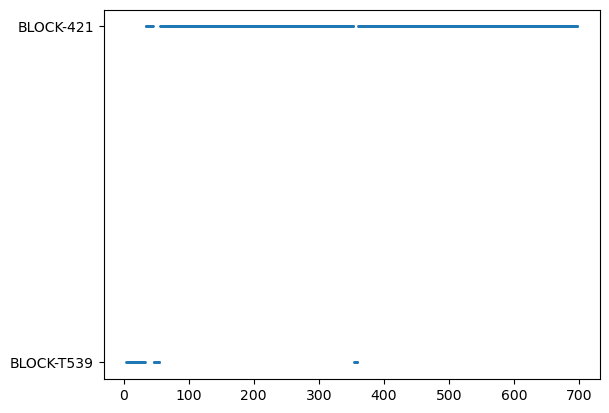

In [6]:
f,ax = plt.subplots(1,1)
_ = ax.scatter(seqs,blocks,s=1)

<a id='State Machine Calculator' ></a>
## State Machine Calculator

This calculator properly tracks changes in Z4 and Vmode5, accounting for:
- The actual sequence number gaps between images
- The lag between measurements and corrections (seq_num_corr)
- Flags for non-sequential images

In [7]:
# calculate_state_machine() defined in Analysis Code section above

<a id='PID Simulation' ></a>
## PID Loop Simulation

Simulate a PID controller to compare with actual system behavior.

**Process:**
1. Process Variable (PV) = z4_at_correction * 1.35
2. PID Controller with kappaP=0.18, kappaI=0.022 or 0.00
3. Manipulated Variable (MV) = output of PID controller

**PID Equation:**
```
MV[i] = kappaP * PV[i] + kappaI * sum(PV[0:i])
```

In [8]:
# simulate_pid_loop() defined in Analysis Code section above

In [9]:
# Calculate state machine
state_df = calculate_state_machine(seqs, z4_fwhm_corrected, vmode5_raw, vmode5_fwhm,combo_dz, seq_num_corr)

# Add block information to state_df
state_df['block'] = blocks

# Add band and filter_change to state_df
state_df['band'] = bands
state_df['filter_change'] = filter_change

# Add PID simulation
print('\nSimulating PID loop...')
kappaI = 0.000
pv, mv, mv_p, mv_i, pv_used_flag = simulate_pid_loop(seqs, seq_num_corr, z4_fwhm_corrected,
                                        kappaP=kappaP, kappaI=kappaI, pv_scale=1.0)

# Add PID variables to state_df
state_df['pv'] = pv
state_df['mv'] = mv
state_df['mv_p'] = mv_p
state_df['mv_i'] = mv_i
state_df['pv_used_flag'] = pv_used_flag

# compare mv to delta_vmode5_fwhm
state_df['delta_mv'] = (--state_df['mv']+state_df['delta_vmode5_fwhm'])


# Display summary
print("State Machine Summary:")
print(f"Total images: {len(state_df)}")
print(f"Images with sequence gaps: {state_df['seq_gap_flag'].sum()}")
print(f"Images with correction gaps: {state_df['corr_gap_flag'].sum()}")
print(f"Images without correction gaps: {(~state_df['corr_gap_flag']).sum()}")
print(f"Filter changes: {state_df['filter_change'].sum()}")
print(f"\nPID Simulation:")
print(f"  PV range: [{np.nanmin(pv):.3f}, {np.nanmax(pv):.3f}]")
print(f"  MV range: [{np.nanmin(mv):.3f}, {np.nanmax(mv):.3f}]")
print(f"  MV_P range: [{np.nanmin(mv_p):.3f}, {np.nanmax(mv_p):.3f}]")
print(f"  MV_I range: [{np.nanmin(mv_i):.3f}, {np.nanmax(mv_i):.3f}]")
print(f"  PV used: {pv_used_flag.sum()} / {len(pv_used_flag)} images")
print(f"\nLag distribution:")
print(state_df['lag'].value_counts().sort_index())
print(f"\nFirst few rows:")
state_df.head(10)


Simulating PID loop...
State Machine Summary:
Total images: 694
Images with sequence gaps: 1
Images with correction gaps: 10
Images without correction gaps: 684
Filter changes: 14

PID Simulation:
  PV range: [-0.759, 2.569]
  MV range: [-0.137, 0.462]
  MV_P range: [-0.137, 0.462]
  MV_I range: [-0.000, -0.000]
  PV used: 593 / 694 images

Lag distribution:
lag
1.0       10
2.0       71
3.0      572
4.0       20
5.0       11
6.0        2
41.0       1
42.0       1
43.0       1
269.0      1
270.0      1
527.0      1
528.0      1
529.0      1
Name: count, dtype: int64

First few rows:


,seq,seq_num_corr,z4_corrected,vmode5_raw,vmode5_fwhm,combo_dz,delta_z4,delta_vmode5_raw,delta_vmode5_fwhm,delta_combo_dz,...,lag,block,band,filter_change,pv,mv,mv_p,mv_i,pv_used_flag,delta_mv
0,4.0,0.0,1.882539,0.000000,0.000000,-0.000000,0.000000,0.000000,0.000000,0.000000,...,4.0,BLOCK-T539,i_39,False,0.000000,0.000000,0.000000,0.0,False,0.000000
1,5.0,0.0,2.008171,0.000000,0.000000,-0.000000,0.125633,0.000000,0.000000,0.000000,...,5.0,BLOCK-T539,i_39,False,0.000000,0.000000,0.000000,0.0,False,0.000000
2,6.0,4.0,2.569299,-2.415408,-3.260801,208.968710,0.561127,-2.415408,-3.260801,208.968710,...,2.0,BLOCK-T539,i_39,False,1.882539,0.338857,0.338857,0.0,True,-2.921944
3,7.0,4.0,2.654899,-2.415408,-3.260801,208.968710,0.085600,0.000000,0.000000,0.000000,...,3.0,BLOCK-T539,i_39,False,0.000000,0.000000,0.000000,0.0,False,0.000000
4,8.0,6.0,0.474473,-3.828979,-5.169122,341.773264,-2.180426,-1.413571,-1.908321,132.804554,...,2.0,BLOCK-T539,i_39,False,2.569299,0.462474,0.462474,0.0,True,-1.445847
5,9.0,6.0,0.447398,-3.828979,-5.169122,341.773264,-0.027075,0.000000,0.000000,0.000000,...,3.0,BLOCK-T539,i_39,False,0.000000,0.000000,0.000000,0.0,False,0.000000
6,10.0,8.0,0.246009,-4.069943,-5.494423,415.397901,-0.201389,-0.240964,-0.325301,73.624637,...,2.0,BLOCK-T539,i_39,False,0.474473,0.085405,0.085405,0.0,True,-0.239896
7,11.0,8.0,0.289223,-4.069943,-5.494423,415.397901,0.043214,0.000000,0.000000,0.000000,...,3.0,BLOCK-T539,i_39,False,0.000000,0.000000,0.000000,0.0,False,0.000000
8,12.0,10.0,0.106717,-4.193610,-5.661373,421.756662,-0.182507,-0.123666,-0.166949,6.358761,...,2.0,BLOCK-T539,i_39,False,0.246009,0.044282,0.044282,0.0,True,-0.122668
9,13.0,10.0,0.114901,-4.193610,-5.661373,421.756662,0.008184,0.000000,0.000000,0.000000,...,3.0,BLOCK-T539,i_39,False,0.000000,0.000000,0.000000,0.0,False,0.000000


### Examine specific sequence range

In [10]:
# Print state machine output for specific sequence range
seq_lo = 40  # Change these values to examine different ranges
seq_hi = 60

# Filter to sequence range
mask = (state_df['seq'] >= seq_lo) & (state_df['seq'] <= seq_hi)
range_df = state_df[mask].copy()

print(f"\nState machine output for sequences {seq_lo} to {seq_hi}:")
print(f"Number of images in range: {len(range_df)}")
print("\nColumns: seq, seq_num_corr, lag, z4_corrected, vmode5_norm, z4_at_correction")
print("         seq_gap_flag, corr_gap_flag, mv\n")

# Display with all relevant columns
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.width', None)      # Don't wrap lines
pd.set_option('display.max_columns', None)  # Show all columns

display(range_df[['seq', 'seq_num_corr', 'lag', 'z4_corrected', 'vmode5_raw','vmode5_fwhm', 
                  'delta_z4', 'delta_vmode5_raw', 'delta_vmode5_fwhm','z4_at_correction', 
                  'seq_gap_flag', 'corr_gap_flag', 'mv','delta_mv']])

# Reset display options
pd.reset_option('display.max_rows')
pd.reset_option('display.width')
pd.reset_option('display.max_columns')


State machine output for sequences 40 to 60:
Number of images in range: 21

Columns: seq, seq_num_corr, lag, z4_corrected, vmode5_norm, z4_at_correction
         seq_gap_flag, corr_gap_flag, mv



,seq,seq_num_corr,lag,z4_corrected,vmode5_raw,vmode5_fwhm,delta_z4,delta_vmode5_raw,delta_vmode5_fwhm,z4_at_correction,seq_gap_flag,corr_gap_flag,mv,delta_mv
36,40.0,39.0,1.0,-0.325615,-3.832961,-5.174497,-0.047028,0.002635,0.003558,-0.278588,False,False,-0.050146,-0.046588
37,41.0,0.0,41.0,-0.744063,-3.832961,-5.174497,-0.418447,0.000000,0.000000,NaN,False,True,0.000000,0.000000
38,42.0,0.0,42.0,-0.759424,-3.832961,-5.174497,-0.015362,0.000000,0.000000,NaN,False,True,0.000000,0.000000
39,43.0,0.0,43.0,-0.780294,-3.832961,-5.174497,-0.020870,0.000000,0.000000,NaN,False,True,0.000000,0.000000
40,44.0,41.0,3.0,-0.570245,-3.730508,-5.036186,0.210049,0.102453,0.138311,-0.744063,False,False,-0.133931,0.004380
41,45.0,42.0,3.0,-0.354356,-3.625468,-4.894382,0.215889,0.105040,0.141804,-0.759424,False,False,-0.136696,0.005107
42,46.0,44.0,2.0,-0.209338,-3.491260,-4.713201,0.145018,0.134208,0.181181,-0.570245,False,False,-0.102644,0.078537
43,47.0,44.0,3.0,-0.249302,-3.491260,-4.713201,-0.039964,0.000000,0.000000,-0.570245,False,False,0.000000,0.000000
44,48.0,46.0,2.0,-0.189422,-3.372807,-4.553289,0.059880,0.118453,0.159912,-0.209338,False,False,-0.037681,0.122231
45,49.0,46.0,3.0,-0.189425,-3.372807,-4.553289,-0.000003,0.000000,0.000000,-0.209338,False,False,0.000000,0.000000


## Original Validation Plots

These plots recreate the original analysis using the new state machine calculations.

### Plot 1: Z4, Combo_dz, and Vmode5 vs Sequence

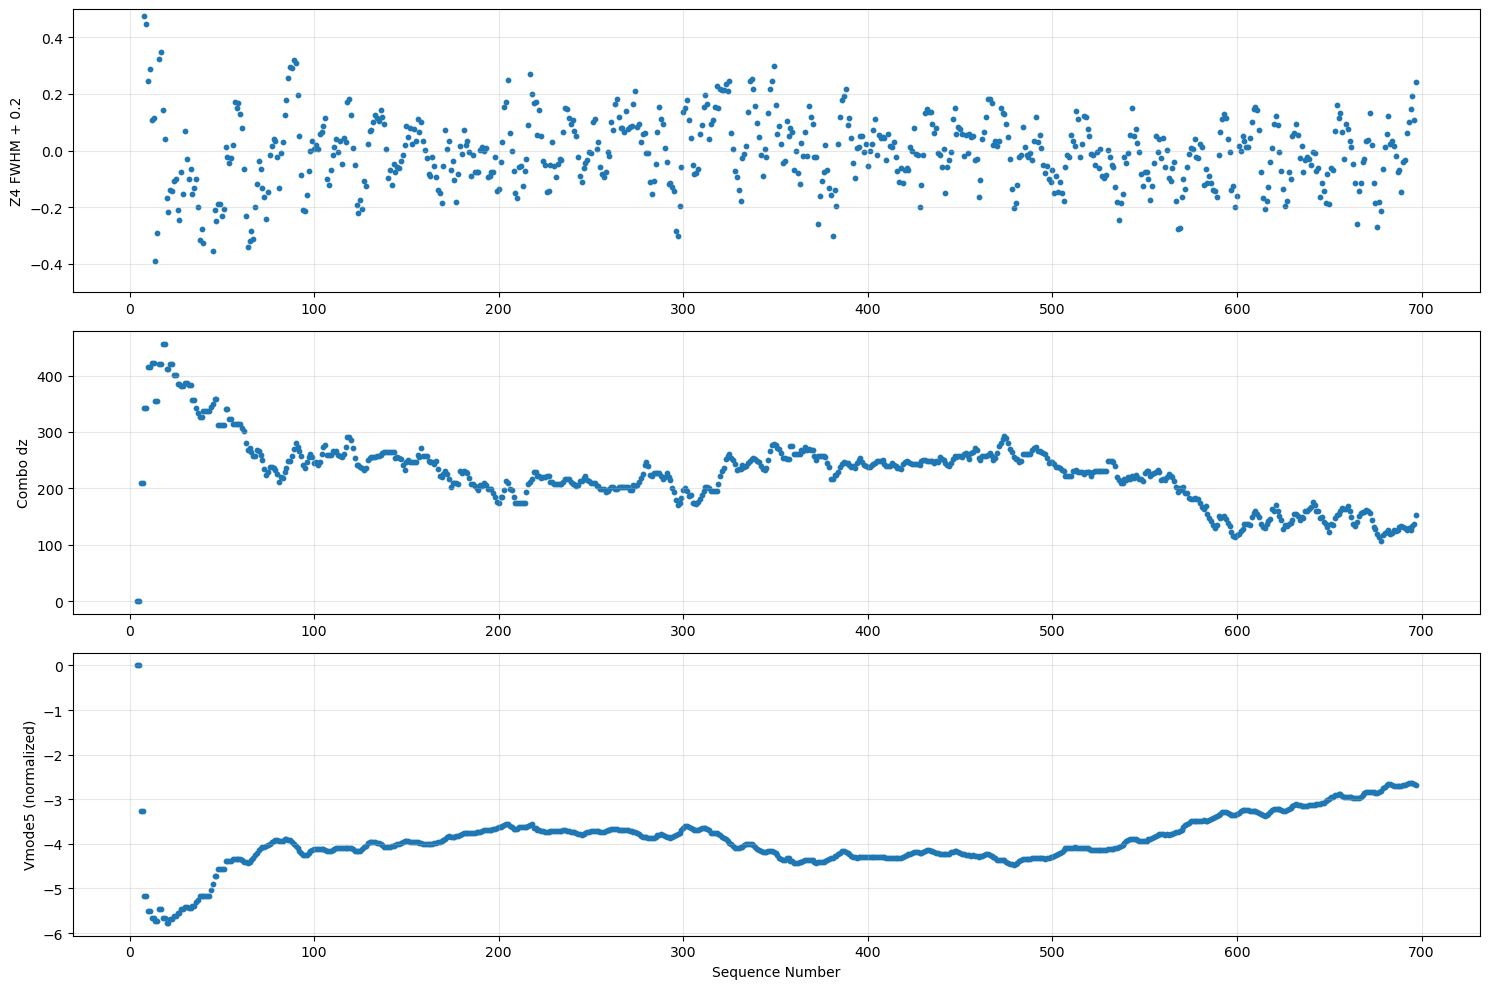

In [11]:
# Calculate combo_dz from dof_state
M2_dz = dof_state[:, label_index('M2_dz')]
Cam_dz = dof_state[:, label_index('Cam_dz')]
combo_dz = -0.53 * M2_dz - 0.84 * Cam_dz

# Three panel plot
f, ax = plt.subplots(3, 1, figsize=(15, 10))

# Panel 1: Z4 corrected
ax[0].scatter(state_df['seq'], state_df['z4_corrected'], s=10)
ax[0].set_ylabel('Z4 FWHM + 0.2')
ax[0].set_ylim(-0.5, 0.5)
ax[0].grid(True, alpha=0.3)

# Panel 2: Combo dz
ax[1].scatter(seqs, combo_dz, s=10)
ax[1].set_ylabel('Combo dz')
ax[1].grid(True, alpha=0.3)

# Panel 3: Vmode5
ax[2].scatter(state_df['seq'], state_df['vmode5_fwhm'], s=10)
ax[2].set_ylabel('Vmode5 (normalized)')
ax[2].set_xlabel('Sequence Number')
ax[2].grid(True, alpha=0.3)

plt.tight_layout()

### Plot 2: Z4, Diff(Combo_dz), and Diff(Vmode5) vs Sequence

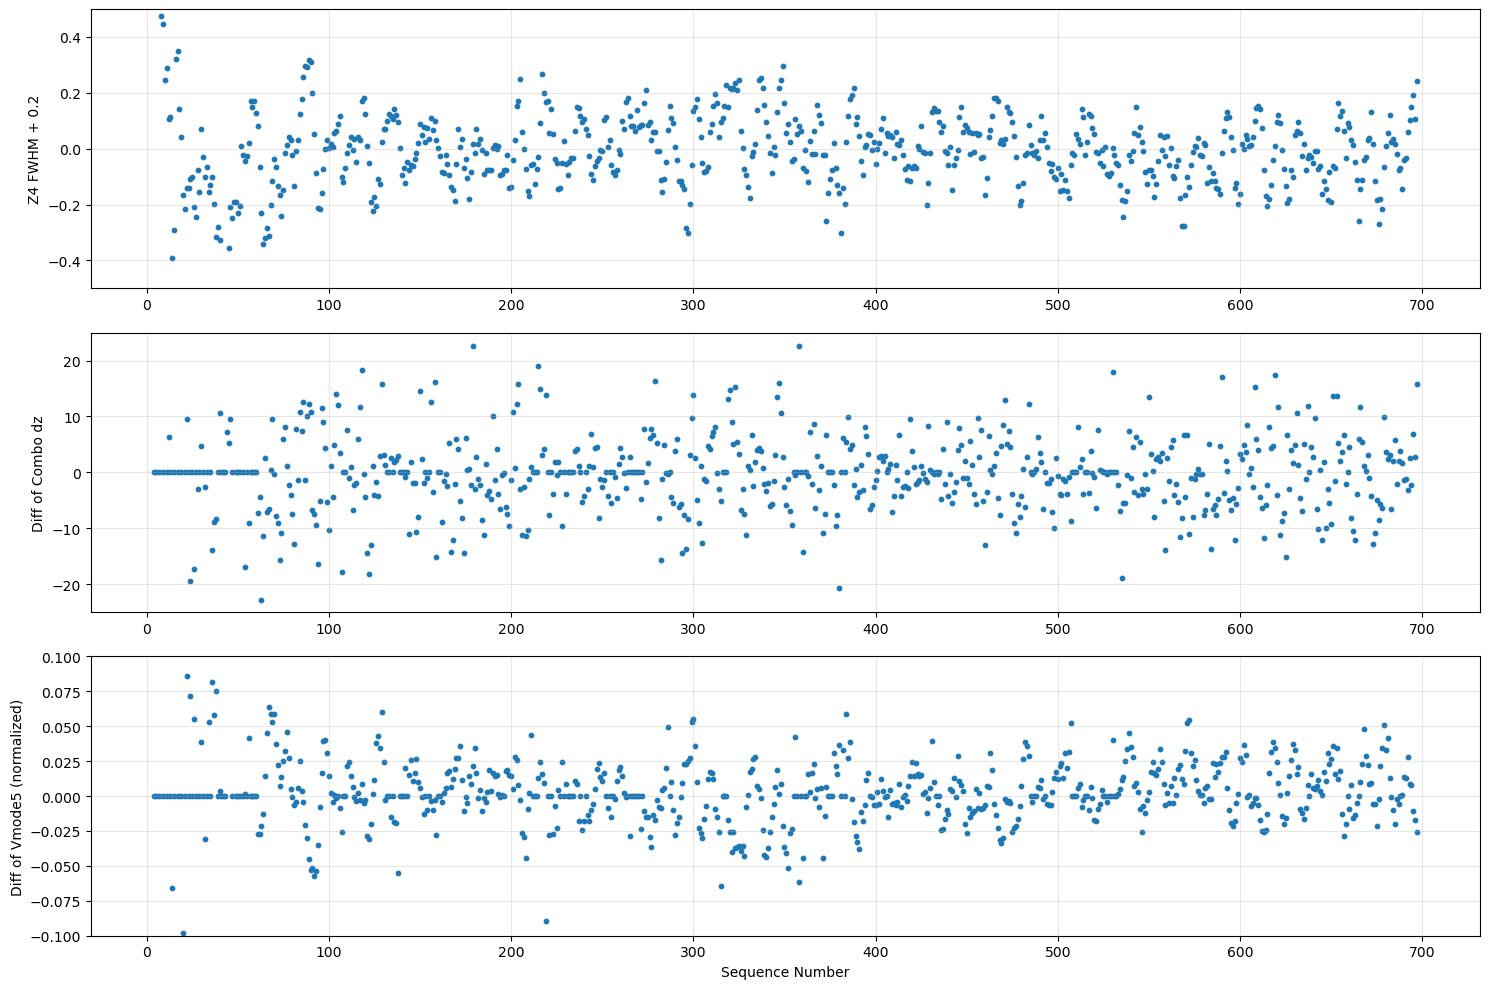

In [12]:
# Three panel plot
f, ax = plt.subplots(3, 1, figsize=(15, 10))

# Panel 1: Z4 corrected
ax[0].scatter(state_df['seq'], state_df['z4_corrected'], s=10)
ax[0].set_ylabel('Z4 FWHM + 0.2')
ax[0].set_ylim(-0.5, 0.5)
ax[0].grid(True, alpha=0.3)

# Panel 2: Diff of Combo dz (from state machine)
ax[1].scatter(state_df['seq'], state_df['delta_combo_dz'], s=10)
ax[1].set_ylabel('Diff of Combo dz')
ax[1].set_ylim(-25., 25.)
ax[1].grid(True, alpha=0.3)

# Panel 3: Diff of Vmode5
ax[2].scatter(state_df['seq'], state_df['delta_vmode5_fwhm'], s=10)
ax[2].set_ylabel('Diff of Vmode5 (normalized)')
ax[2].set_xlabel('Sequence Number')
ax[2].set_ylim(-0.1, 0.1)
ax[2].grid(True, alpha=0.3)

plt.tight_layout()

### Plot 3: Z4 and Diff(Vmode5) Overlapping - With and Without Lag

Text(0.5, 1.0, 'Z4 and Delta Vmode5 (no lag)')

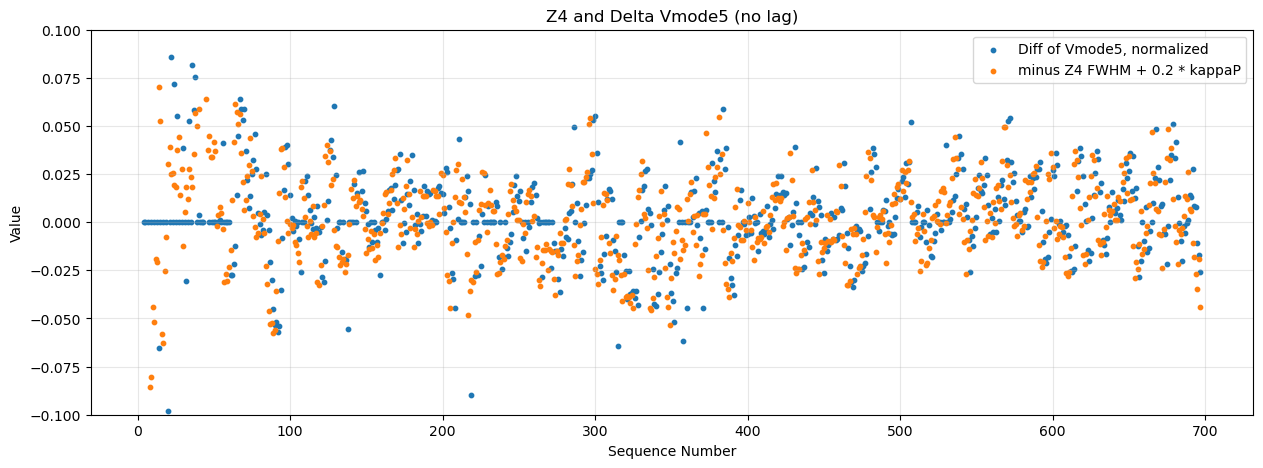

In [13]:
# Plot without offset (no lag)
f, ax = plt.subplots(1, 1, figsize=(15, 5))

ax.scatter(state_df['seq'], state_df['delta_vmode5_fwhm'], s=10, label='Diff of Vmode5, normalized')
ax.scatter(state_df['seq'], -state_df['z4_corrected']*kappaP, s=10, label='minus Z4 FWHM + 0.2 * kappaP')
ax.set_xlabel('Sequence Number')
ax.set_ylabel('Value')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(-0.1, 0.1)
plt.title('Z4 and Delta Vmode5 (no lag)')

Text(0.5, 1.0, 'Z4 and Delta Vmode5 (with lag)')

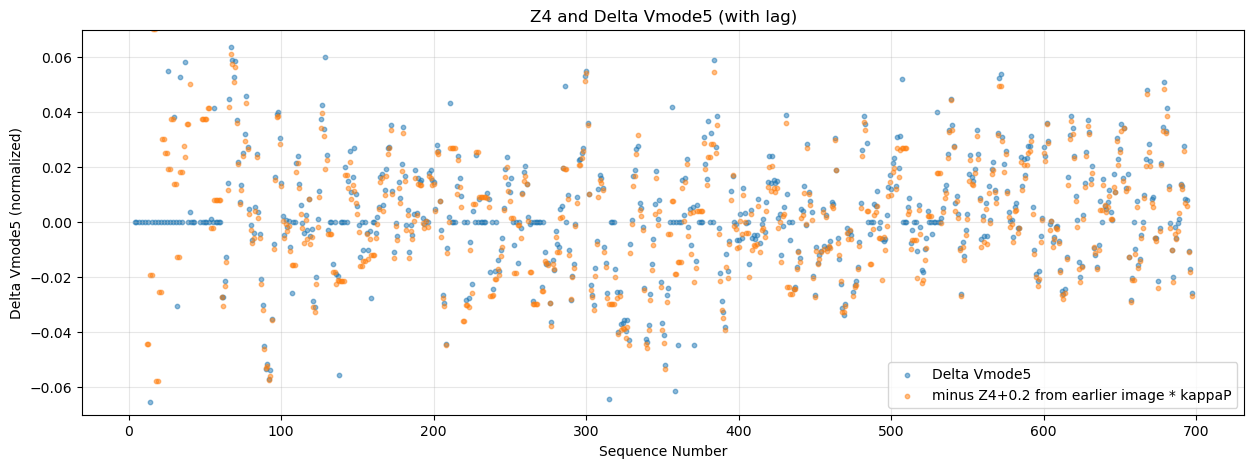

In [14]:
f, ax = plt.subplots(1, 1, figsize=(15, 5))

ax.scatter(state_df['seq'], state_df['delta_vmode5_fwhm'], s=10, label='Delta Vmode5', alpha=0.5)
ax.scatter(state_df['seq'], -state_df['z4_at_correction']*kappaP, s=10, label='minus Z4+0.2 from earlier image * kappaP', alpha=0.5)
ax.set_xlabel('Sequence Number')
ax.set_ylabel('Delta Vmode5 (normalized)')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(-0.07, 0.07)
plt.title('Z4 and Delta Vmode5 (with lag)')

### Plot 4: Correlation Plot - Z4 vs Diff(Vmode5) with Lag Offset

Text(0.5, 1.0, 'Causality: Earlier Z4 → Later Vmode5 change (n=684)')

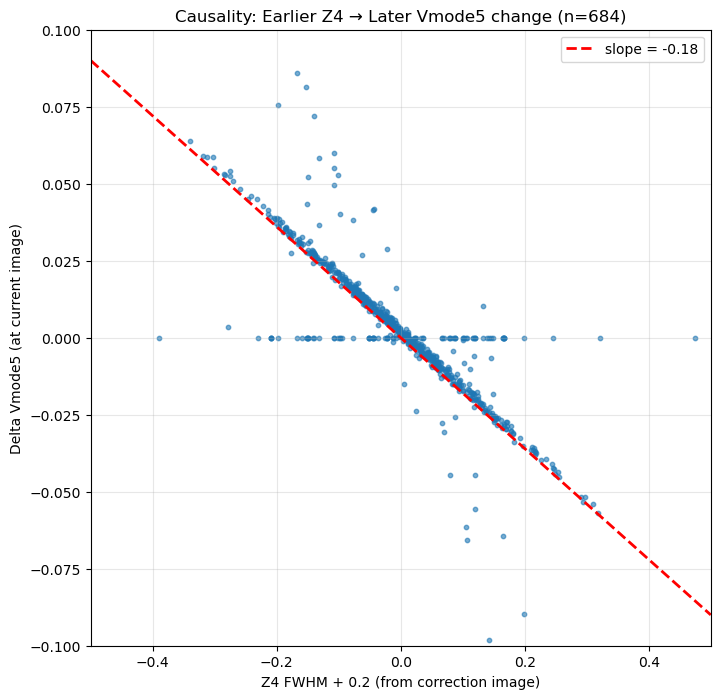

In [15]:
# Correlation plot with correct causality
# Z4 from earlier image (at seq_num_corr) vs change in vmode5 at current image

f, ax = plt.subplots(1, 1, figsize=(8, 8))

# Filter out images with gaps
good_data = state_df[
    (~state_df['seq_gap_flag']) & 
    (~state_df['corr_gap_flag'])
].copy()

ax.scatter(good_data['z4_at_correction'], 
           good_data['delta_vmode5_fwhm'], 
           s=10, alpha=0.6)

ax.axline((0, 0), slope=-0.18, color='red', linestyle='--', linewidth=2, label='slope = -0.18')

ax.set_xlabel('Z4 FWHM + 0.2 (from correction image)')
ax.set_ylabel('Delta Vmode5 (at current image)')
ax.set_xlim(-0.5, 0.5)
ax.set_ylim(-0.1, 0.1)
#ax.set_aspect('equal')
ax.legend()
ax.grid(True, alpha=0.3)
n_good = len(good_data)
plt.title(f'Causality: Earlier Z4 → Later Vmode5 change (n={n_good})')

### Plot 5 Compare delta_vmode5 (caused by z4_at_correction from a previous image) with delta_z4

Number of good images with lag=3: 684


Text(0.5, 1.0, 'Delta Z4 vs Delta Vmode5')

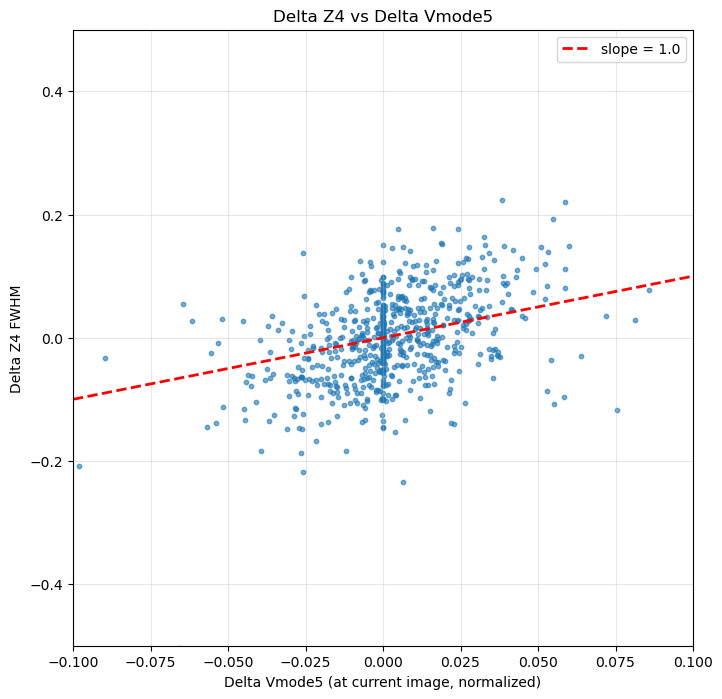

In [16]:
# Filter for lag=3 and no gaps
good_data = state_df[
    (~state_df['seq_gap_flag']) & 
    (~state_df['corr_gap_flag'])
].copy()

print(f"Number of good images with lag=3: {len(good_data)}")

f, ax = plt.subplots(1, 1, figsize=(8, 8))

ax.scatter(good_data['delta_vmode5_fwhm'], good_data['delta_z4'], s=10, alpha=0.6)
ax.axline((0, 0), slope=1.0, color='red', linestyle='--', linewidth=2, label='slope = 1.0')

ax.set_xlabel('Delta Vmode5 (at current image, normalized)')
ax.set_ylabel('Delta Z4 FWHM')
ax.set_xlim(-0.1, 0.1)
ax.set_ylim(-0.5, 0.5)
#ax.set_aspect('equal')
ax.legend()
ax.grid(True, alpha=0.3)
plt.title(f'Delta Z4 vs Delta Vmode5')

### RANSAC Fit to find robust slope


RANSAC Fit Results:
Slope: 1.3929
Intercept: -0.0047
Number of inliers: 666 / 672
Observed slope: 1.3929


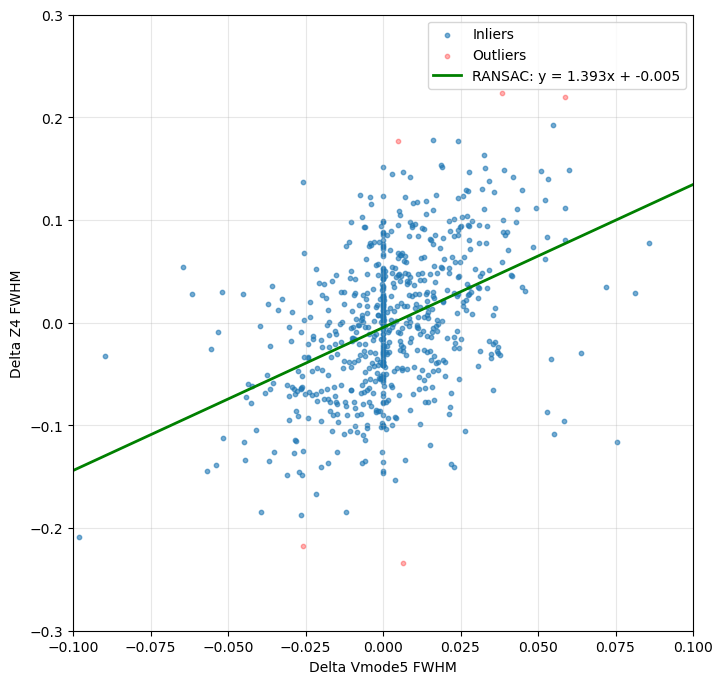

In [17]:
# Prepare data for RANSAC
good_data = state_df[
    (~state_df['seq_gap_flag']) & 
    (~state_df['corr_gap_flag']) & (np.abs(state_df['delta_vmode5_fwhm'])<0.1) 
].copy()
x_data = good_data['delta_vmode5_fwhm'].to_numpy().reshape(-1, 1)
y_data = good_data['delta_z4'].to_numpy()

# Fit with RANSAC
ransac = RANSACRegressor(
    estimator=LinearRegression(),
    min_samples=50,
    residual_threshold=0.175,
    max_trials=1000,
    random_state=42
)
ransac.fit(x_data, y_data)

# Get results
inlier_mask = ransac.inlier_mask_
slope = ransac.estimator_.coef_[0]
intercept = ransac.estimator_.intercept_

# Plot
f, ax = plt.subplots(1, 1, figsize=(8, 8))

ax.scatter(x_data[inlier_mask], y_data[inlier_mask], s=10, label='Inliers', alpha=0.6)
ax.scatter(x_data[~inlier_mask], y_data[~inlier_mask], s=10, color='red', label='Outliers', alpha=0.3)

# Fitted line
x_fit = np.linspace(-0.5, 0.5, 100)
y_fit = slope * x_fit + intercept
ax.plot(x_fit, y_fit, 'g-', linewidth=2, label=f'RANSAC: y = {slope:.3f}x + {intercept:.3f}')

ax.set_xlabel('Delta Vmode5 FWHM')
ax.set_ylabel('Delta Z4 FWHM')
limscale = 1.
ax.set_xlim(-0.1*limscale, 0.1*limscale)
ax.set_ylim(-0.3*limscale, 0.3*limscale)
#ax.set_aspect('equal')
ax.legend()
ax.grid(True, alpha=0.3)

print(f'\nRANSAC Fit Results:')
print(f'Slope: {slope:.4f}')
print(f'Intercept: {intercept:.4f}')
print(f'Number of inliers: {inlier_mask.sum()} / {len(y_data)}')
print(f'Observed slope: {slope:.4f}')


In [18]:
# Analyze correlation for different lag values
for lag_val in [2, 3]:
    lag_data = state_df[
        (state_df['lag'] == lag_val) & 
        (~state_df['seq_gap_flag']) & 
        (~state_df['corr_gap_flag']) & (np.abs(state_df['delta_vmode5_fwhm'])<0.1)  
    ]
    
    if len(lag_data) > 50:
        corr = np.corrcoef(lag_data['delta_vmode5_fwhm'], lag_data['delta_z4'])[0, 1]
        print(f'\nLag = {lag_val}:')
        print(f'  Number of images: {len(lag_data)}')
        print(f'  Correlation: {corr:.3f}')
        print(f'  RMS delta_z4: {lag_data["delta_z4"].std():.4f}')
        print(f'  RMS delta_vmode5: {lag_data["delta_vmode5_fwhm"].std():.4f}')


Lag = 2:
  Number of images: 61
  Correlation: 0.514
  RMS delta_z4: 0.1140
  RMS delta_vmode5: 0.0367

Lag = 3:
  Number of images: 570
  Correlation: 0.473
  RMS delta_z4: 0.0699
  RMS delta_vmode5: 0.0198


## PID Simulation Comparison

Compare the simulated PID output with actual Vmode5 changes

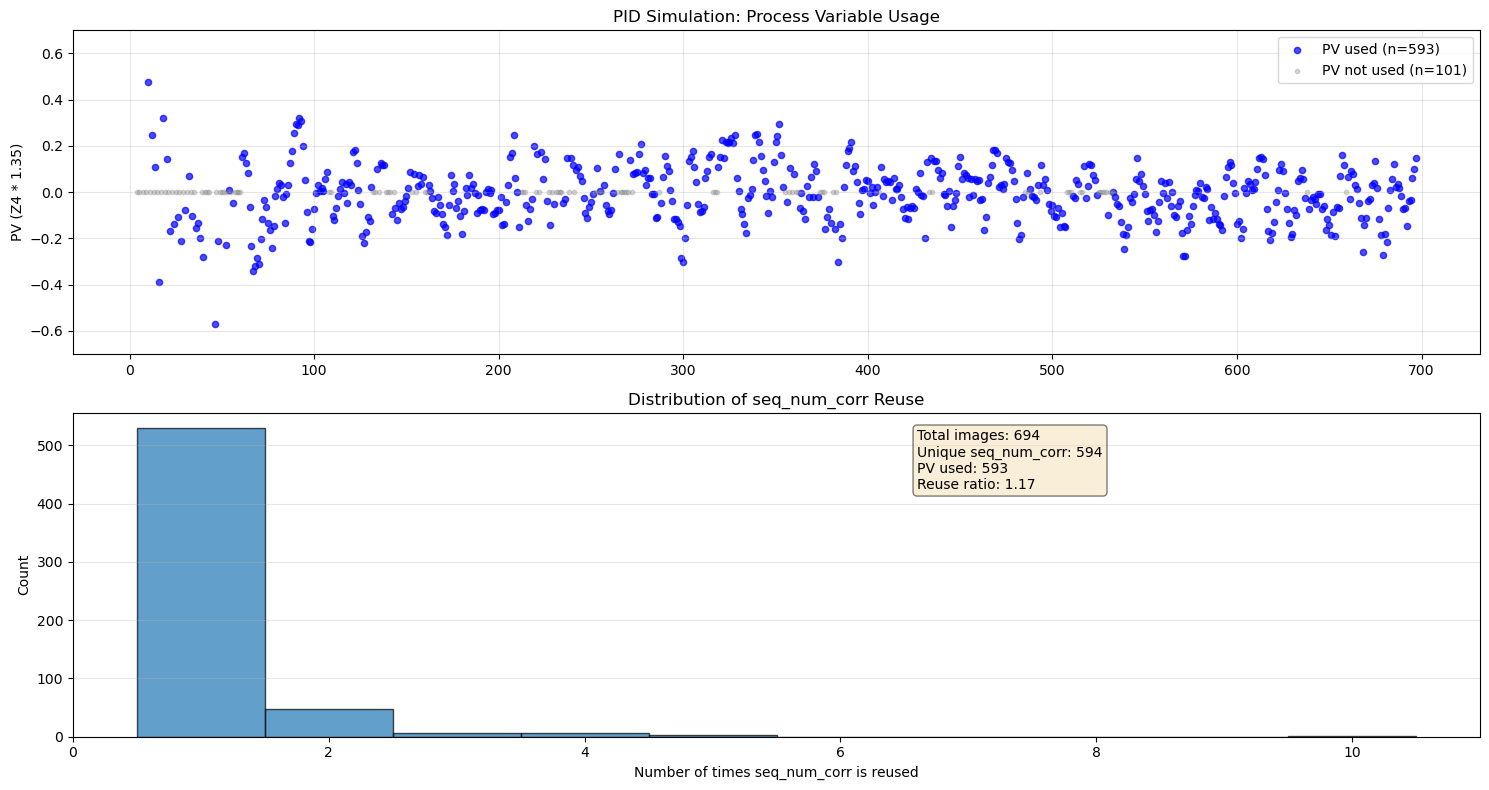

In [19]:
# Diagnostic: Show which images used PV for correction
f, ax = plt.subplots(2, 1, figsize=(15, 8))

# Panel 1: PV with usage flags
used_mask = state_df['pv_used_flag']
not_used_mask = ~used_mask

ax[0].scatter(state_df.loc[used_mask, 'seq'], 
              state_df.loc[used_mask, 'pv'], 
              s=20, alpha=0.7, label=f'PV used (n={used_mask.sum()})', color='blue')
ax[0].scatter(state_df.loc[not_used_mask, 'seq'], 
              state_df.loc[not_used_mask, 'pv'], 
              s=10, alpha=0.3, label=f'PV not used (n={not_used_mask.sum()})', color='gray')
ax[0].set_ylabel('PV (Z4 * 1.35)')
ax[0].set_ylim(-0.7, 0.7)
ax[0].legend()
ax[0].grid(True, alpha=0.3)
ax[0].set_title('PID Simulation: Process Variable Usage')

# Panel 2: Show seq_num_corr uniqueness
# Count how many times each seq_num_corr appears
seq_corr_counts = state_df['seq_num_corr'].value_counts()
ax[1].hist(seq_corr_counts.values, bins=np.arange(1, seq_corr_counts.max()+2)-0.5, 
           edgecolor='black', alpha=0.7)
ax[1].set_xlabel('Number of times seq_num_corr is reused')
ax[1].set_ylabel('Count')
ax[1].set_title('Distribution of seq_num_corr Reuse')
ax[1].grid(True, alpha=0.3, axis='y')

# Add text with statistics
unique_corr = state_df['seq_num_corr'].nunique()
total_images = len(state_df)
ax[1].text(0.6, 0.95, 
           f'Total images: {total_images}\n'
           f'Unique seq_num_corr: {unique_corr}\n'
           f'PV used: {used_mask.sum()}\n'
           f'Reuse ratio: {total_images/unique_corr:.2f}',
           transform=ax[1].transAxes, va='top',
           bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()

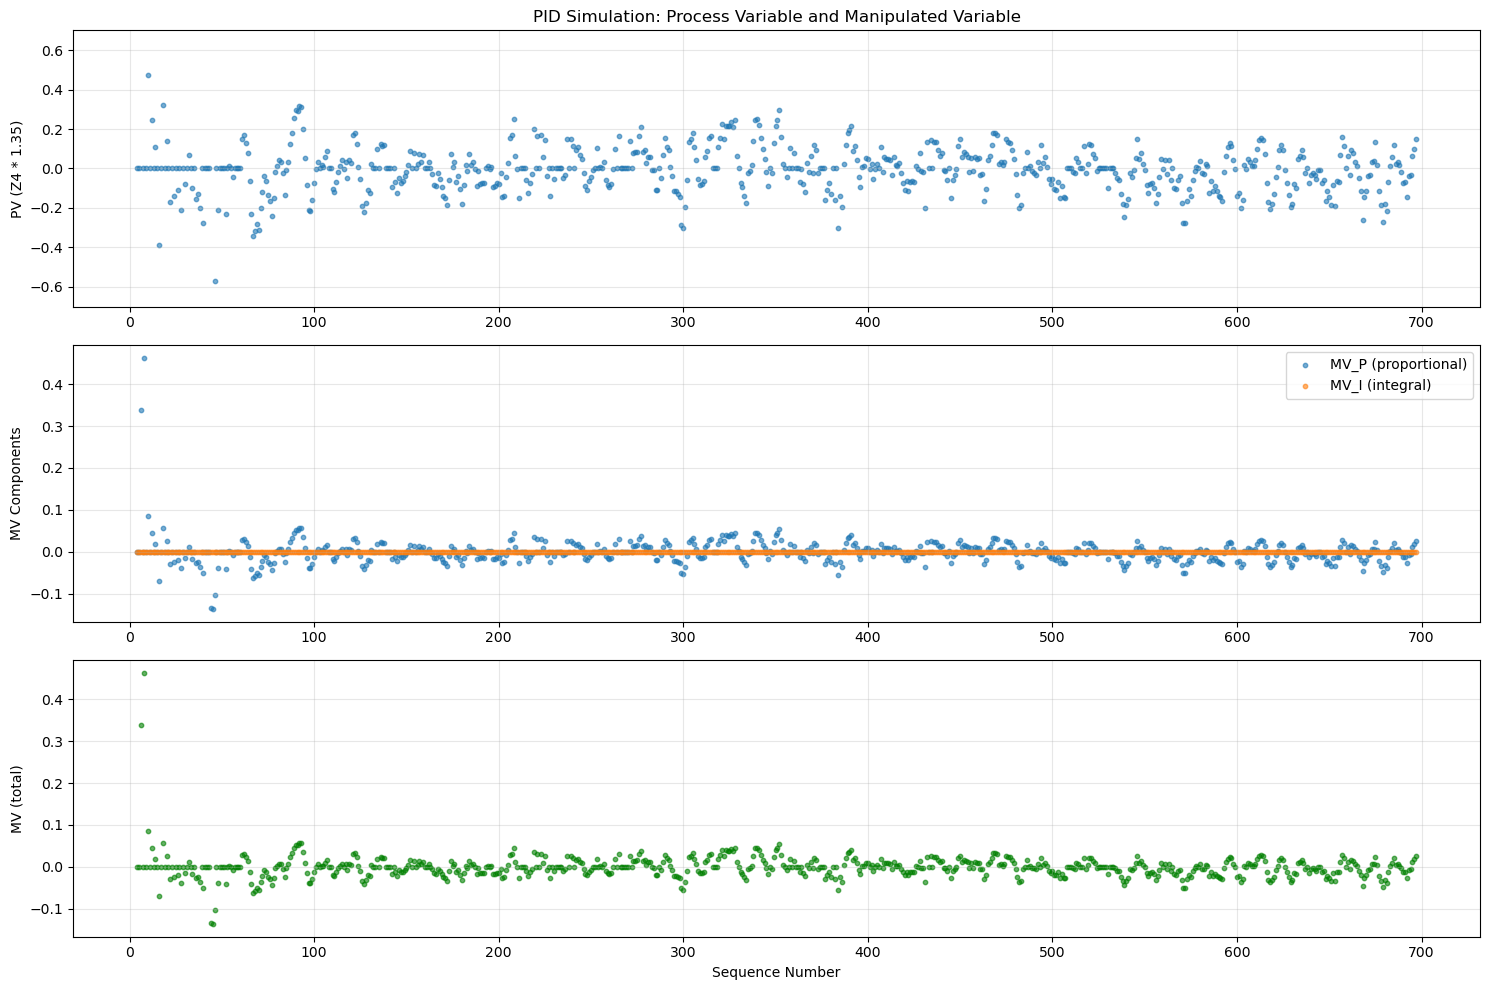

In [20]:
# Plot PV and MV vs sequence
f, ax = plt.subplots(3, 1, figsize=(15, 10))

# Panel 1: Process Variable (PV)
ax[0].scatter(state_df['seq'], state_df['pv'], s=10, alpha=0.6)
ax[0].set_ylabel('PV (Z4 * 1.35)')
ax[0].set_ylim(-0.7, 0.7)
ax[0].grid(True, alpha=0.3)
ax[0].set_title('PID Simulation: Process Variable and Manipulated Variable')

# Panel 2: MV components
ax[1].scatter(state_df['seq'], state_df['mv_p'], s=10, alpha=0.6, label='MV_P (proportional)')
ax[1].scatter(state_df['seq'], state_df['mv_i'], s=10, alpha=0.6, label='MV_I (integral)')
ax[1].set_ylabel('MV Components')
ax[1].legend()
ax[1].grid(True, alpha=0.3)

# Panel 3: Total MV
ax[2].scatter(state_df['seq'], state_df['mv'], s=10, alpha=0.6, color='green')
ax[2].set_ylabel('MV (total)')
ax[2].set_xlabel('Sequence Number')
ax[2].grid(True, alpha=0.3)

plt.tight_layout()

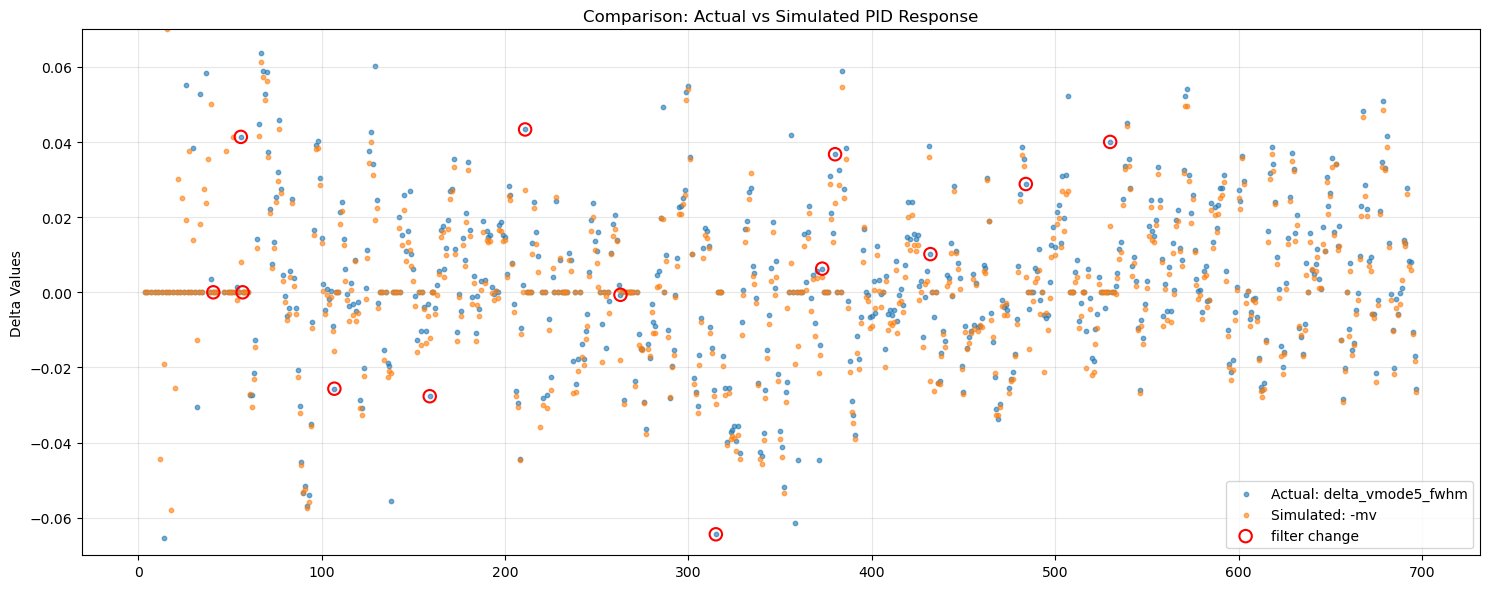

In [21]:
# Compare -mv with delta_vmode5
f, ax = plt.subplots(1, 1, figsize=(15, 6))

# Panel 1: Time series comparison
ax.scatter(state_df['seq'], state_df['delta_vmode5_fwhm'], s=10, alpha=0.6, label='Actual: delta_vmode5_fwhm')
ax.scatter(state_df['seq'], -state_df['mv'], s=10, alpha=0.6, label='Simulated: -mv')

# Highlight filter change points
fc_mask = state_df['filter_change']
if fc_mask.any():
    ax.scatter(state_df.loc[fc_mask, 'seq'], state_df.loc[fc_mask, 'delta_vmode5_fwhm'],
               s=80, facecolors='none', edgecolors='red', linewidths=1.5, label='filter change', zorder=5)

ax.set_ylabel('Delta Values')
ax.set_ylim(-0.07,0.07)
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_title('Comparison: Actual vs Simulated PID Response')

plt.tight_layout()

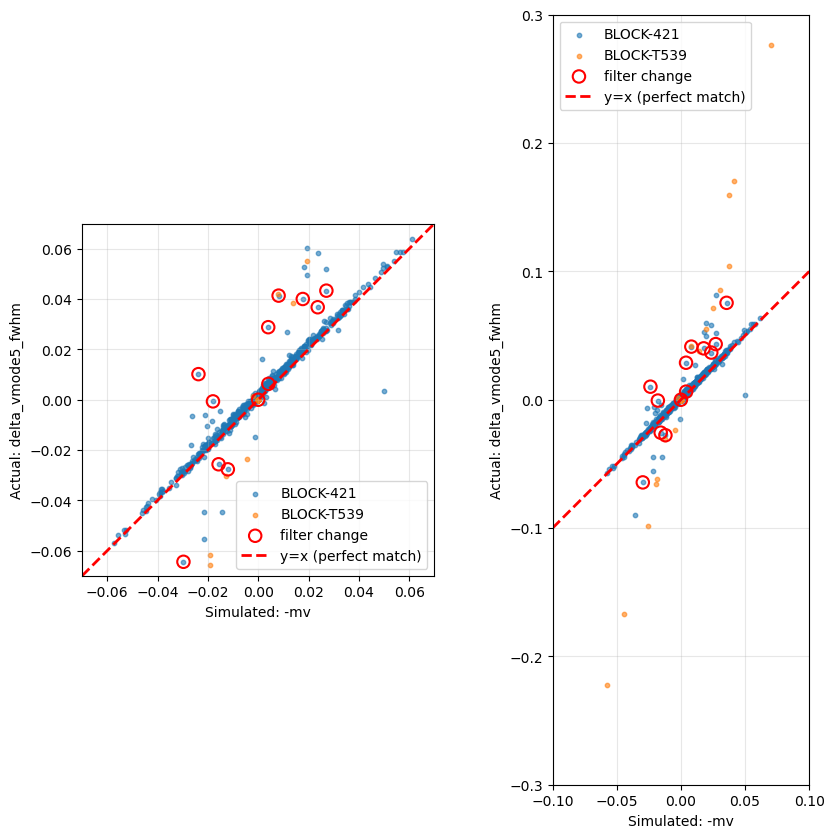

In [22]:

f,ax = plt.subplots(1,2,figsize=(10,10))

xlims = [0.07,0.10]
ylims = [0.07,0.30]

for i in range(2):
    
    # Panel 2: Correlation plot, color-coded by block
    good_mask = ~state_df['seq_gap_flag'] & ~state_df['corr_gap_flag']
    good_data = state_df[good_mask]
    for block_name, group in good_data.groupby('block'):
        ax[i].scatter(-group['mv'], 
                  group['delta_vmode5_fwhm'], 
                  s=10, alpha=0.6, label=block_name)

    # Highlight filter change points
    fc_good = good_data[good_data['filter_change']]
    if len(fc_good) > 0:
        ax[i].scatter(-fc_good['mv'], fc_good['delta_vmode5_fwhm'],
                      s=80, facecolors='none', edgecolors='red', linewidths=1.5,
                      label='filter change', zorder=5)

    ax[i].axline((0, 0), slope=1, color='red', linestyle='--', linewidth=2, label='y=x (perfect match)')
    ax[i].set_xlabel('Simulated: -mv')
    ax[i].set_ylabel('Actual: delta_vmode5_fwhm')
    ax[i].set_xlim(-xlims[i],xlims[i])
    ax[i].set_ylim(-ylims[i],ylims[i])
    ax[i].set_aspect('equal')
    ax[i].legend()
    ax[i].grid(True, alpha=0.3)


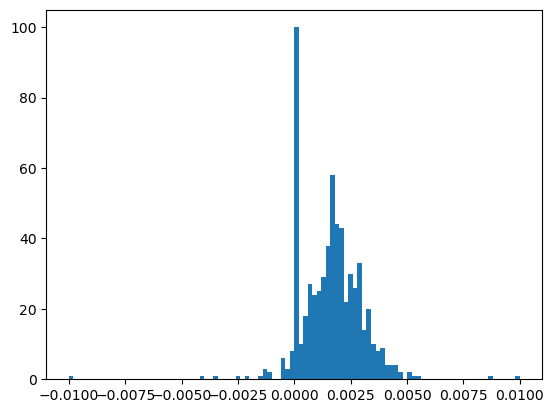

In [23]:
# Panel 3: difference in -mv vs. delta_vmode5_fwhm
good_mask = ~state_df['seq_gap_flag'] & ~state_df['corr_gap_flag']
good_data = state_df[good_mask]
f,ax = plt.subplots(1,1)
 
_ = ax.hist(good_data['delta_mv'], bins=100,range=(-0.01,0.01))


### Print out info on outliers

In [24]:

# Filter for visits of interest
mask = np.abs(good_data['delta_mv']-0.002)>0.004
out_df = good_data[mask].copy()

# Display with all relevant columns
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.width', None)      # Don't wrap lines
pd.set_option('display.max_columns', None)  # Show all columns

display(out_df[['seq', 'seq_num_corr', 'lag', 'z4_corrected', 'vmode5_raw','vmode5_fwhm', 
                  'delta_z4', 'delta_vmode5_fwhm','z4_at_correction', 
                  'seq_gap_flag', 'corr_gap_flag', 'mv','delta_mv','block']])

# Reset display options
pd.reset_option('display.max_rows')
pd.reset_option('display.width')
pd.reset_option('display.max_columns')

,seq,seq_num_corr,lag,z4_corrected,vmode5_raw,vmode5_fwhm,delta_z4,delta_vmode5_fwhm,z4_at_correction,seq_gap_flag,corr_gap_flag,mv,delta_mv,block
2,6.0,4.0,2.0,2.569299,-2.415408,-3.260801,0.561127,-3.260801,1.882539,False,False,0.338857,-2.921944,BLOCK-T539
4,8.0,6.0,2.0,0.474473,-3.828979,-5.169122,-2.180426,-1.908321,2.569299,False,False,0.462474,-1.445847,BLOCK-T539
6,10.0,8.0,2.0,0.246009,-4.069943,-5.494423,-0.201389,-0.325301,0.474473,False,False,0.085405,-0.239896,BLOCK-T539
8,12.0,10.0,2.0,0.106717,-4.193610,-5.661373,-0.182507,-0.166949,0.246009,False,False,0.044282,-0.122668,BLOCK-T539
10,14.0,12.0,2.0,-0.389457,-4.242148,-5.726899,-0.504358,-0.065526,0.106717,False,False,0.019209,-0.046317,BLOCK-T539
12,16.0,14.0,2.0,0.321651,-4.037289,-5.450341,0.612352,0.276558,-0.389457,False,False,-0.070102,0.206456,BLOCK-T539
14,18.0,16.0,2.0,0.141526,-4.201836,-5.672479,-0.206498,-0.222138,0.321651,False,False,0.057897,-0.164241,BLOCK-T539
16,20.0,18.0,2.0,-0.167371,-4.274466,-5.770530,-0.208606,-0.098051,0.141526,False,False,0.025475,-0.072576,BLOCK-T539
18,22.0,20.0,2.0,-0.140031,-4.210903,-5.684719,0.077421,0.085811,-0.167371,False,False,-0.030127,0.055684,BLOCK-T539
20,24.0,22.0,2.0,-0.107338,-4.157679,-5.612867,0.034960,0.071852,-0.140031,False,False,-0.025206,0.046646,BLOCK-T539


## PID Loop Stability Analysis

Investigate whether the current proportional gain (kappaP=0.18) is causing
delay-induced oscillation with the ~3-image lag.

**Approach:**
1. Autocorrelation and power spectrum of Z4 to detect oscillation signature
2. Reconstruct the open-loop disturbance, then re-simulate the closed loop
   with different gains to find the optimal kappaP

### 1. Autocorrelation and Power Spectrum of Z4

For a proportional controller with dead time d=3, the characteristic equation
`λ³ + kappaP = 0` gives oscillation at period ≈ 6 images (twice the delay).
Look for this signature in the data.

Using quality-masked data only (no seq/corr gaps, BLOCK-421, no filter changes).

Quality mask for stability analysis:
  Selected: 627 / 694 images
  Excluded by seq_gap:       1
  Excluded by corr_gap:      10
  Excluded by filter_change: 14
  Excluded by block:         46
  Contiguity: 15 gaps in selected sequences (max gap = 13 images)

Z4 statistics (quality data, N=627):
  RMS = 0.1177, Std = 0.1175, MAD(σ) = 0.1063

Autocorrelation of Z4 at key lags:
  lag  1: +0.792
  lag  2: +0.558
  lag  3: +0.274
  lag  4: +0.042
  lag  5: -0.105
  lag  6: -0.160
  lag  7: -0.147
  lag  8: -0.105
  lag  9: -0.042
  lag 10: +0.032
  lag 12: +0.123

Analytical prediction (λ³ + 0.18 = 0):
  |λ| = 0.18^(1/3) = 0.565
  Oscillation period = 6 images
  Damping per period = |λ|^6 = 0.032


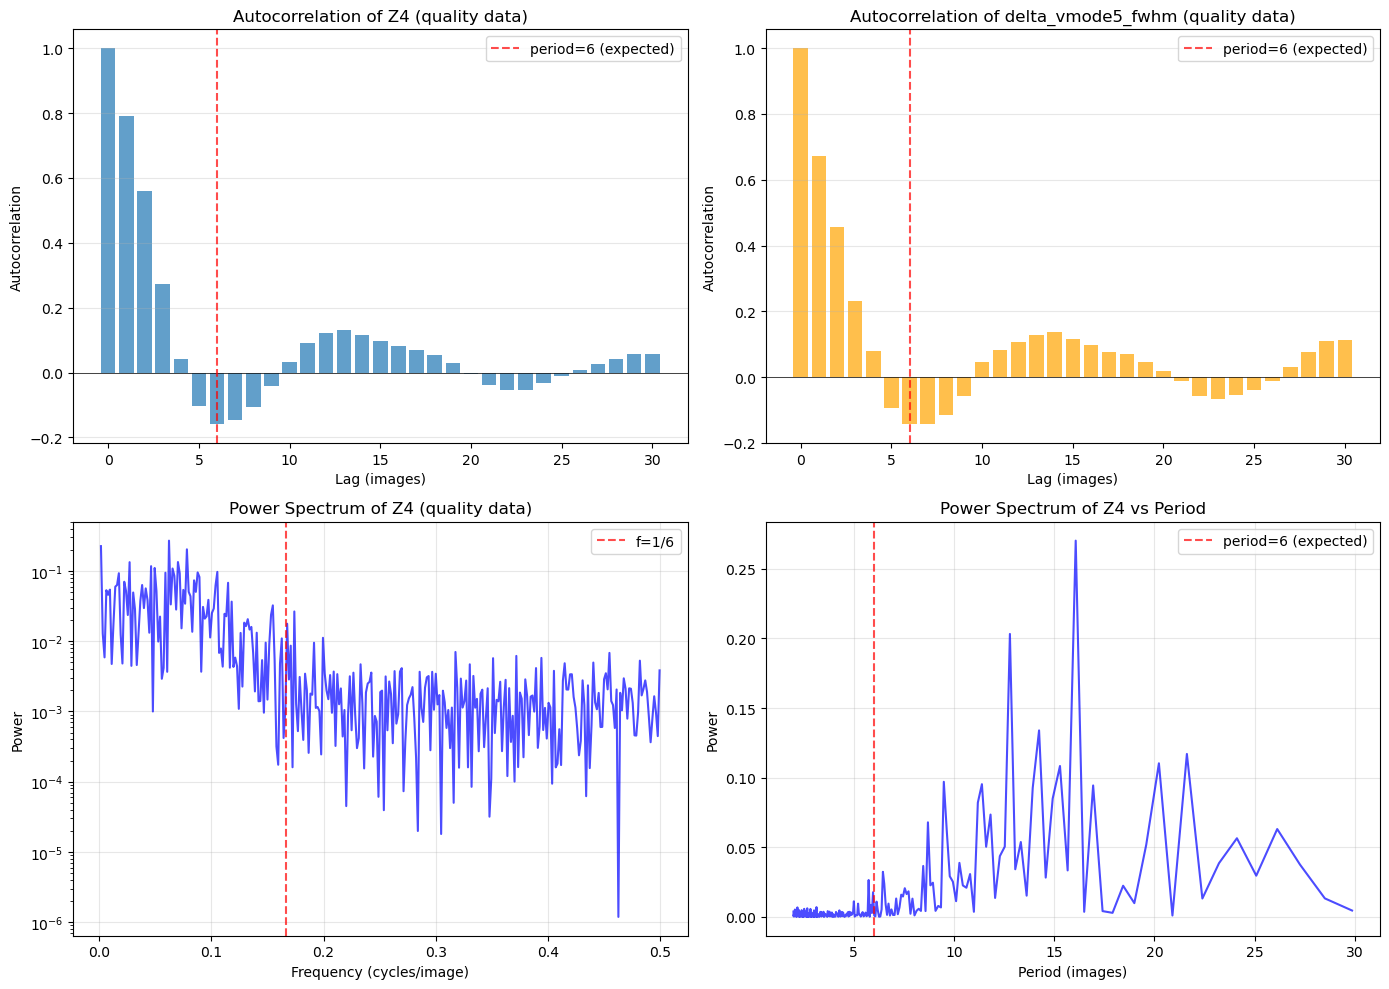

In [25]:
# Quality mask for stability analysis
# Require: no seq gaps, no corr gaps, BLOCK-421, no filter changes
quality_mask = (~state_df['seq_gap_flag'] & ~state_df['corr_gap_flag'] &
                (state_df['block'] == 'BLOCK-421') & ~state_df['filter_change'])
quality_idx = np.where(quality_mask)[0]  # indices into original arrays

print(f'Quality mask for stability analysis:')
print(f'  Selected: {quality_mask.sum()} / {len(quality_mask)} images')
print(f'  Excluded by seq_gap:       {state_df["seq_gap_flag"].sum()}')
print(f'  Excluded by corr_gap:      {state_df["corr_gap_flag"].sum()}')
print(f'  Excluded by filter_change: {state_df["filter_change"].sum()}')
print(f'  Excluded by block:         {(state_df["block"] != "BLOCK-421").sum()}')

# Autocorrelation and power spectrum of Z4 on quality data
# autocorrelation() defined in Analysis Code section above
z4_qual = z4_fwhm_corrected[quality_idx]
seqs_qual = seqs[quality_idx]

# Check contiguity
seq_diffs = np.diff(seqs_qual)
n_gaps = np.sum(seq_diffs > 1)
print(f'  Contiguity: {n_gaps} gaps in selected sequences '
      f'(max gap = {seq_diffs.max():.0f} images)' if len(seq_diffs) > 0 else '')

max_lag = 30
acf_z4 = autocorrelation(z4_qual, max_lag)

# Also compute for delta_vmode5_fwhm (the correction signal)
dv5_qual = state_df.loc[quality_idx, 'delta_vmode5_fwhm'].values
acf_dv5 = autocorrelation(dv5_qual, max_lag)

# Power spectrum via FFT
from numpy.fft import rfft, rfftfreq
z4_centered = z4_qual - np.mean(z4_qual)
N = len(z4_centered)
freqs = rfftfreq(N, d=1.0)  # d=1 image spacing
power = np.abs(rfft(z4_centered))**2 / N
periods = np.zeros_like(freqs)
periods[1:] = 1.0 / freqs[1:]

f, ax = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Autocorrelation of Z4
lags = np.arange(max_lag + 1)
ax[0,0].bar(lags, acf_z4, width=0.8, alpha=0.7)
ax[0,0].axhline(0, color='black', linewidth=0.5)
ax[0,0].axvline(6, color='red', linestyle='--', alpha=0.7, label='period=6 (expected)')
ax[0,0].set_xlabel('Lag (images)')
ax[0,0].set_ylabel('Autocorrelation')
ax[0,0].set_title('Autocorrelation of Z4 (quality data)')
ax[0,0].legend()
ax[0,0].grid(True, alpha=0.3, axis='y')

# Panel 2: Autocorrelation of delta_vmode5
ax[0,1].bar(lags, acf_dv5, width=0.8, alpha=0.7, color='orange')
ax[0,1].axhline(0, color='black', linewidth=0.5)
ax[0,1].axvline(6, color='red', linestyle='--', alpha=0.7, label='period=6 (expected)')
ax[0,1].set_xlabel('Lag (images)')
ax[0,1].set_ylabel('Autocorrelation')
ax[0,1].set_title('Autocorrelation of delta_vmode5_fwhm (quality data)')
ax[0,1].legend()
ax[0,1].grid(True, alpha=0.3, axis='y')

# Panel 3: Power spectrum vs frequency
ax[1,0].semilogy(freqs[1:], power[1:], 'b-', alpha=0.7)
ax[1,0].axvline(1/6.0, color='red', linestyle='--', alpha=0.7, label='f=1/6')
ax[1,0].set_xlabel('Frequency (cycles/image)')
ax[1,0].set_ylabel('Power')
ax[1,0].set_title('Power Spectrum of Z4 (quality data)')
ax[1,0].legend()
ax[1,0].grid(True, alpha=0.3)

# Panel 4: Power spectrum vs period (zoomed to interesting range)
period_mask = (periods > 2) & (periods < 30)
ax[1,1].plot(periods[period_mask], power[period_mask], 'b-', alpha=0.7)
ax[1,1].axvline(6, color='red', linestyle='--', alpha=0.7, label='period=6 (expected)')
ax[1,1].set_xlabel('Period (images)')
ax[1,1].set_ylabel('Power')
ax[1,1].set_title('Power Spectrum of Z4 vs Period')
ax[1,1].legend()
ax[1,1].grid(True, alpha=0.3)

plt.tight_layout()

# Print key autocorrelation values
print(f'\nZ4 statistics (quality data, N={len(z4_qual)}):')
print(f'  RMS = {np.sqrt(np.mean(z4_qual**2)):.4f}, Std = {np.std(z4_qual):.4f}, '
      f'MAD(σ) = {median_abs_deviation(z4_qual, scale="normal"):.4f}')
print(f'\nAutocorrelation of Z4 at key lags:')
for lag_val in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12]:
    print(f'  lag {lag_val:2d}: {acf_z4[lag_val]:+.3f}')

# Analytical prediction: for λ^3 + K = 0 with K=0.18
K = kappaP
lam_mag = K**(1/3)
lam_period = 6  # 2*pi / (pi/3) = 6
print(f'\nAnalytical prediction (λ³ + {K} = 0):')
print(f'  |λ| = {K}^(1/3) = {lam_mag:.3f}')
print(f'  Oscillation period = {lam_period} images')
print(f'  Damping per period = |λ|^{lam_period} = {lam_mag**lam_period:.3f}')

### 2. Closed-Loop Gain Sweep Simulation

Reconstruct the "open-loop" disturbance signal, then re-simulate the closed loop
with different proportional gains to find the optimal kappaP.

**Model:** `z4_measured = z4_disturbance + vmode5_fwhm` (unit coupling in FWHM units)

**Reconstruction:** `z4_disturbance = z4_measured - vmode5_fwhm`

**Re-simulation:** Use the same lag structure (seq_num_corr) from the real data,
but apply corrections using the simulated z4 at each step with the trial gain.

Disturbance range: [1.88, 5.92]
Disturbance at start: 1.883
Disturbance at end:   2.929
This is what Z4 would be with no AOS corrections (kappaP=0)


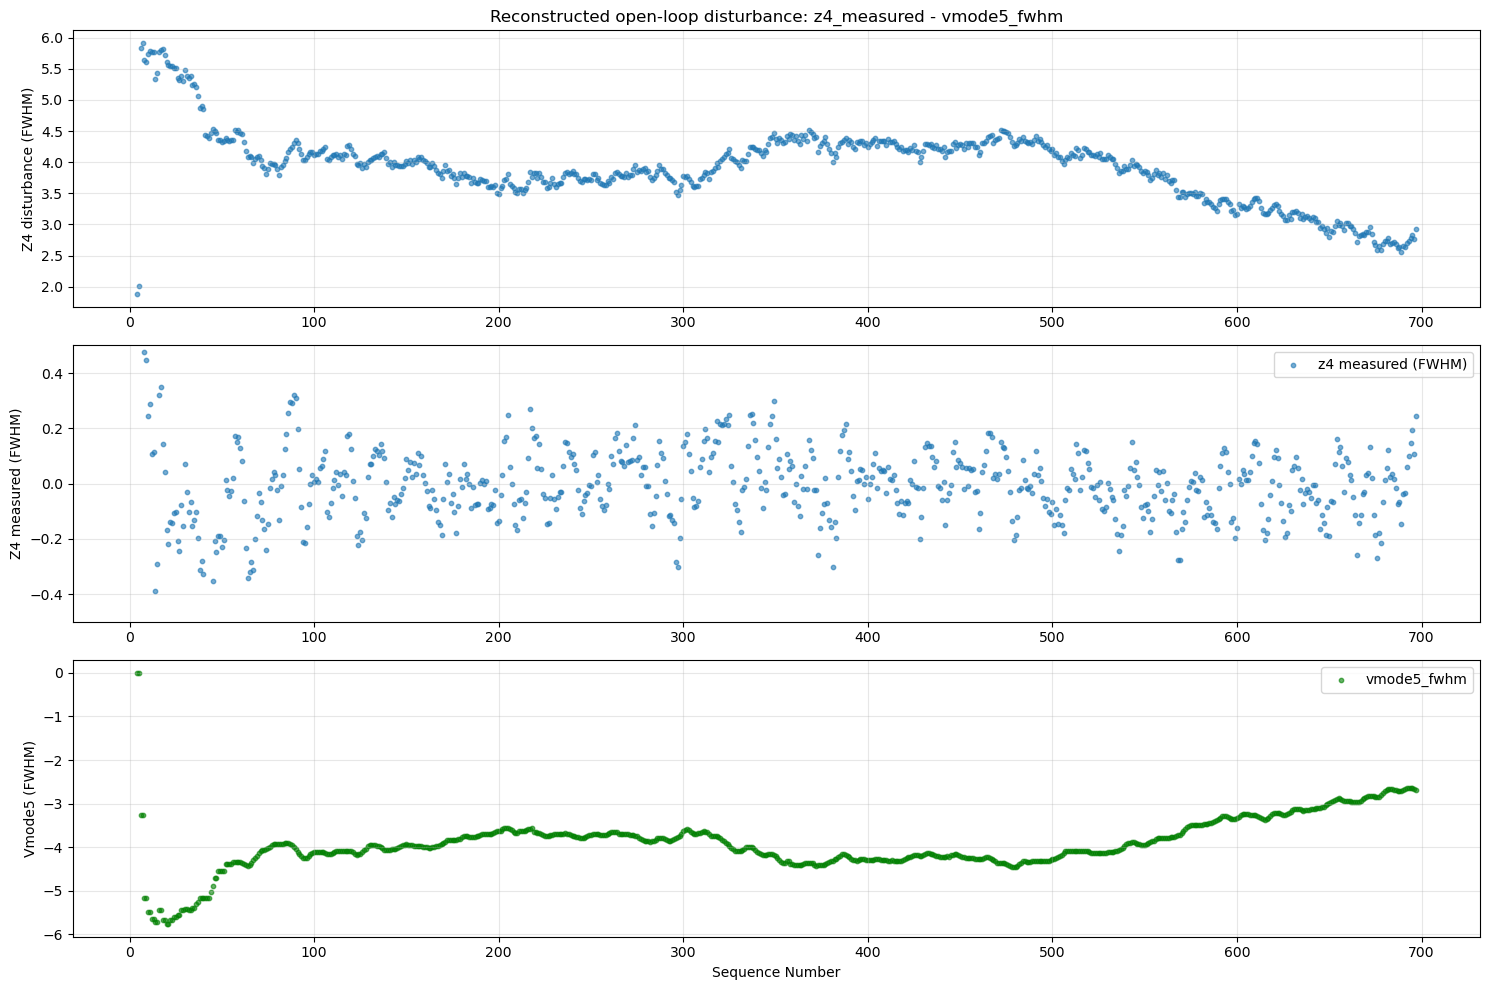

In [26]:
# Reconstruct the open-loop disturbance
# z4_disturbance = z4_measured - G * vmode5_fwhm  (G=1 in FWHM units)
z4_disturbance = z4_fwhm_corrected - vmode5_fwhm

f, ax = plt.subplots(3, 1, figsize=(15, 10))

ax[0].scatter(seqs, z4_disturbance, s=10, alpha=0.6)
ax[0].set_ylabel('Z4 disturbance (FWHM)')
ax[0].set_title('Reconstructed open-loop disturbance: z4_measured - vmode5_fwhm')
ax[0].grid(True, alpha=0.3)

ax[1].scatter(seqs, z4_fwhm_corrected, s=10, alpha=0.6, label='z4 measured (FWHM)')
ax[1].set_ylabel('Z4 measured (FWHM)')
ax[1].set_ylim(-0.5, 0.5)
ax[1].legend()
ax[1].grid(True, alpha=0.3)

ax[2].scatter(seqs, vmode5_fwhm, s=10, alpha=0.6, label='vmode5_fwhm', color='green')
ax[2].set_ylabel('Vmode5 (FWHM)')
ax[2].set_xlabel('Sequence Number')
ax[2].legend()
ax[2].grid(True, alpha=0.3)

plt.tight_layout()

print(f'Disturbance range: [{z4_disturbance.min():.2f}, {z4_disturbance.max():.2f}]')
print(f'Disturbance at start: {z4_disturbance[0]:.3f}')
print(f'Disturbance at end:   {z4_disturbance[-1]:.3f}')
print(f'This is what Z4 would be with no AOS corrections (kappaP=0)')

Validation: simulating with kappaP=0.18
  All data (N=694):
    RMS residual           = 0.416654
  Quality data (N=627):
    RMS residual           = 0.028166
    Std residual           = 0.025869
    MAD (sigma equivalent) = 0.004812
    Ratio RMS/MAD          = 5.85
  |residual| > 2σ_MAD: 334 (53.3%)
  |residual| > 3σ_MAD: 176 (28.1%)
  |residual| > 5σ_MAD: 88 (14.0%)


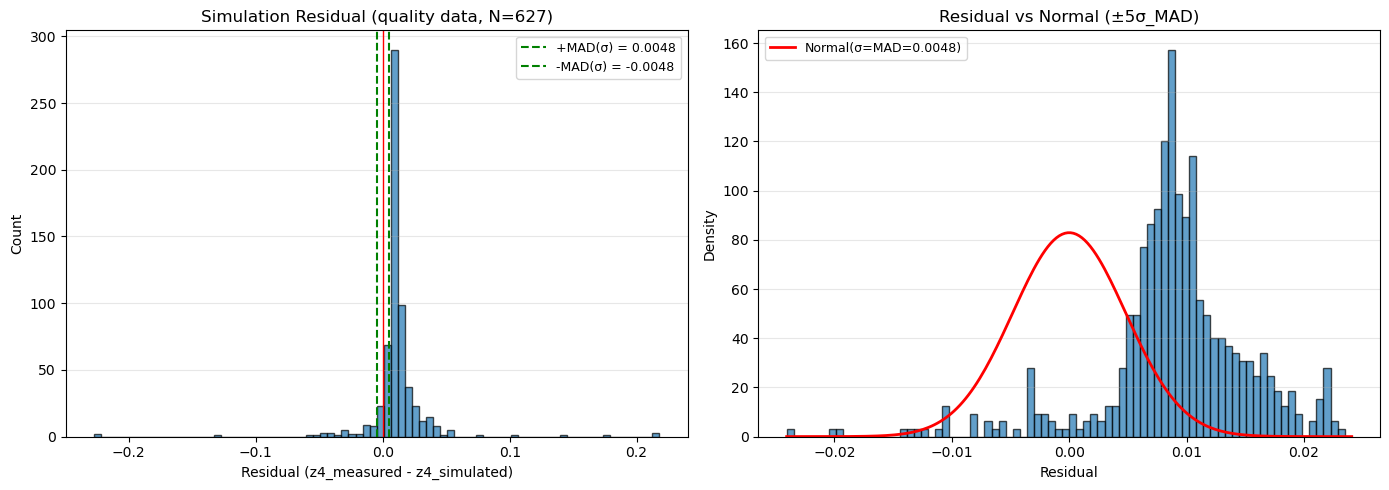

In [27]:
# simulate_closed_loop() defined in Analysis Code section above

# Validate: simulate with actual kappaP=0.18 and compare to measured z4
z4_check, v5_check = simulate_closed_loop(z4_disturbance, vmode5_fwhm[0], seqs,
                                           seq_num_corr, kappaP)
residual = z4_fwhm_corrected - z4_check

# Evaluate on quality data only
residual_qual = residual[quality_idx]
mad_sigma = median_abs_deviation(residual_qual, scale='normal')

print(f'Validation: simulating with kappaP={kappaP}')
print(f'  All data (N={len(residual)}):')
print(f'    RMS residual           = {np.sqrt(np.mean(residual**2)):.6f}')
print(f'  Quality data (N={len(residual_qual)}):')
print(f'    RMS residual           = {np.sqrt(np.mean(residual_qual**2)):.6f}')
print(f'    Std residual           = {np.std(residual_qual):.6f}')
print(f'    MAD (sigma equivalent) = {mad_sigma:.6f}')
print(f'    Ratio RMS/MAD          = {np.sqrt(np.mean(residual_qual**2))/mad_sigma:.2f}')

# Histogram of residual (quality data)
f, ax = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Full range histogram
ax[0].hist(residual_qual, bins=80, edgecolor='black', alpha=0.7)
ax[0].axvline(0, color='red', linestyle='-', linewidth=1)
ax[0].axvline(mad_sigma, color='green', linestyle='--', linewidth=1.5, label=f'+MAD(σ) = {mad_sigma:.4f}')
ax[0].axvline(-mad_sigma, color='green', linestyle='--', linewidth=1.5, label=f'-MAD(σ) = {-mad_sigma:.4f}')
ax[0].set_xlabel('Residual (z4_measured - z4_simulated)')
ax[0].set_ylabel('Count')
ax[0].set_title(f'Simulation Residual (quality data, N={len(residual_qual)})')
ax[0].legend(fontsize=9)
ax[0].grid(True, alpha=0.3, axis='y')

# Panel 2: Zoomed histogram with Gaussian overlay
zoom_range = 5 * mad_sigma
ax[1].hist(residual_qual, bins=80, range=(-zoom_range, zoom_range),
           edgecolor='black', alpha=0.7, density=True)
x_gauss = np.linspace(-zoom_range, zoom_range, 200)
gauss = np.exp(-0.5 * (x_gauss / mad_sigma)**2) / (mad_sigma * np.sqrt(2 * np.pi))
ax[1].plot(x_gauss, gauss, 'r-', linewidth=2, label=f'Normal(σ=MAD={mad_sigma:.4f})')
ax[1].set_xlabel('Residual')
ax[1].set_ylabel('Density')
ax[1].set_title(f'Residual vs Normal (±5σ_MAD)')
ax[1].legend(fontsize=9)
ax[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()

# Count outliers beyond N sigma_MAD
for nsig in [2, 3, 5]:
    n_out = np.sum(np.abs(residual_qual) > nsig * mad_sigma)
    pct = 100 * n_out / len(residual_qual)
    print(f'  |residual| > {nsig}σ_MAD: {n_out} ({pct:.1f}%)')

Gain sweep results (quality data, N=627):
                                 RMS       Std    MAD(σ)   RMS/MAD
        Open loop (kP=0.000)    3.8733    0.4718    0.4151      9.33
          Min MAD (kP=0.160)    0.1199    0.1183    0.1052      1.14
          Min RMS (kP=0.195)    0.1185    0.1173    0.1077      1.10
          Current (kP=0.180)    0.1187    0.1173    0.1062      1.12


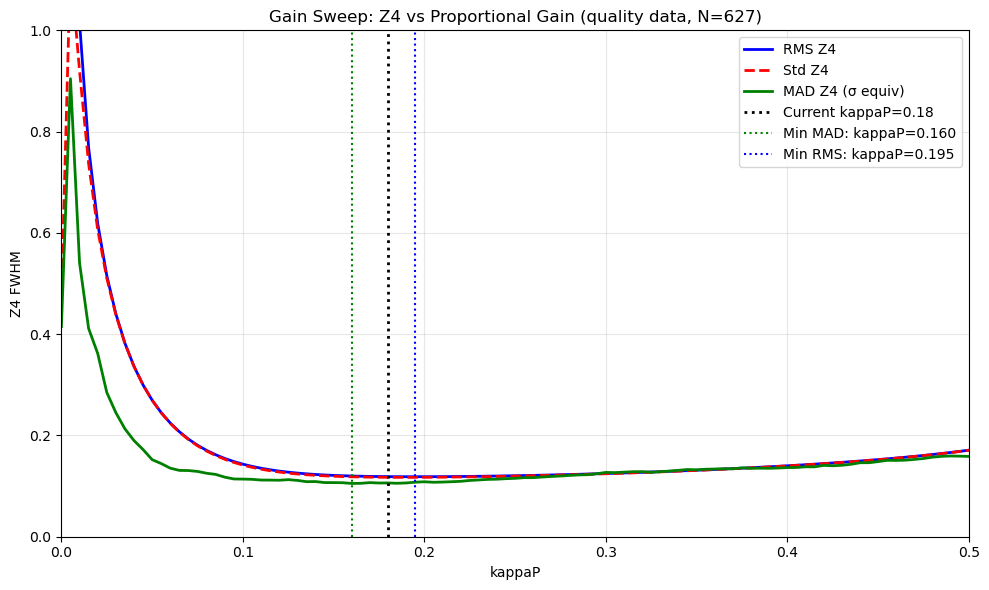

In [28]:
# Gain sweep: simulate closed loop for range of kappaP values
# Evaluate performance on quality data only

kappaP_values = np.arange(0.0, 0.51, 0.005)
rms_z4 = np.zeros(len(kappaP_values))
std_z4 = np.zeros(len(kappaP_values))
mad_z4 = np.zeros(len(kappaP_values))
mean_z4 = np.zeros(len(kappaP_values))

for j, kp in enumerate(kappaP_values):
    z4_sim, _ = simulate_closed_loop(z4_disturbance, vmode5_fwhm[0], seqs,
                                      seq_num_corr, kp)
    z4_qual = z4_sim[quality_idx]
    rms_z4[j] = np.sqrt(np.mean(z4_qual**2))
    std_z4[j] = np.std(z4_qual)
    mad_z4[j] = median_abs_deviation(z4_qual, scale='normal')
    mean_z4[j] = np.mean(np.abs(z4_qual))

# Find optima
min_rms_idx = np.argmin(rms_z4)
min_std_idx = np.argmin(std_z4)
min_mad_idx = np.argmin(mad_z4)

f, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.plot(kappaP_values, rms_z4, 'b-', linewidth=2, label='RMS Z4')
ax.plot(kappaP_values, std_z4, 'r--', linewidth=2, label='Std Z4')
ax.plot(kappaP_values, mad_z4, 'g-', linewidth=2, label='MAD Z4 (σ equiv)')
ax.axvline(kappaP, color='black', linestyle=':', linewidth=2,
           label=f'Current kappaP={kappaP}')
ax.axvline(kappaP_values[min_mad_idx], color='green', linestyle=':', linewidth=1.5,
           label=f'Min MAD: kappaP={kappaP_values[min_mad_idx]:.3f}')
ax.axvline(kappaP_values[min_rms_idx], color='blue', linestyle=':', linewidth=1.5,
           label=f'Min RMS: kappaP={kappaP_values[min_rms_idx]:.3f}')
ax.set_xlabel('kappaP')
ax.set_ylabel('Z4 FWHM')
ax.set_title(f'Gain Sweep: Z4 vs Proportional Gain (quality data, N={len(quality_idx)})')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 0.5)
ax.set_ylim(0, 1)
plt.tight_layout()

# Print comparison table
kp_018_idx = np.argmin(np.abs(kappaP_values - 0.18))
print(f'Gain sweep results (quality data, N={len(quality_idx)}):')
print(f'{"":>26s}  {"RMS":>8s}  {"Std":>8s}  {"MAD(σ)":>8s}  {"RMS/MAD":>8s}')
rows = [
    ('Open loop', 0, 0),
    ('Min MAD', min_mad_idx, kappaP_values[min_mad_idx]),
    ('Min RMS', min_rms_idx, kappaP_values[min_rms_idx]),
    ('Current', kp_018_idx, 0.180),
]
for label, idx, kp_val in rows:
    tag = f'{label:>12s} (kP={kp_val:.3f})'
    print(f'  {tag:>26s}  {rms_z4[idx]:8.4f}  {std_z4[idx]:8.4f}  {mad_z4[idx]:8.4f}  {rms_z4[idx]/mad_z4[idx]:8.2f}')

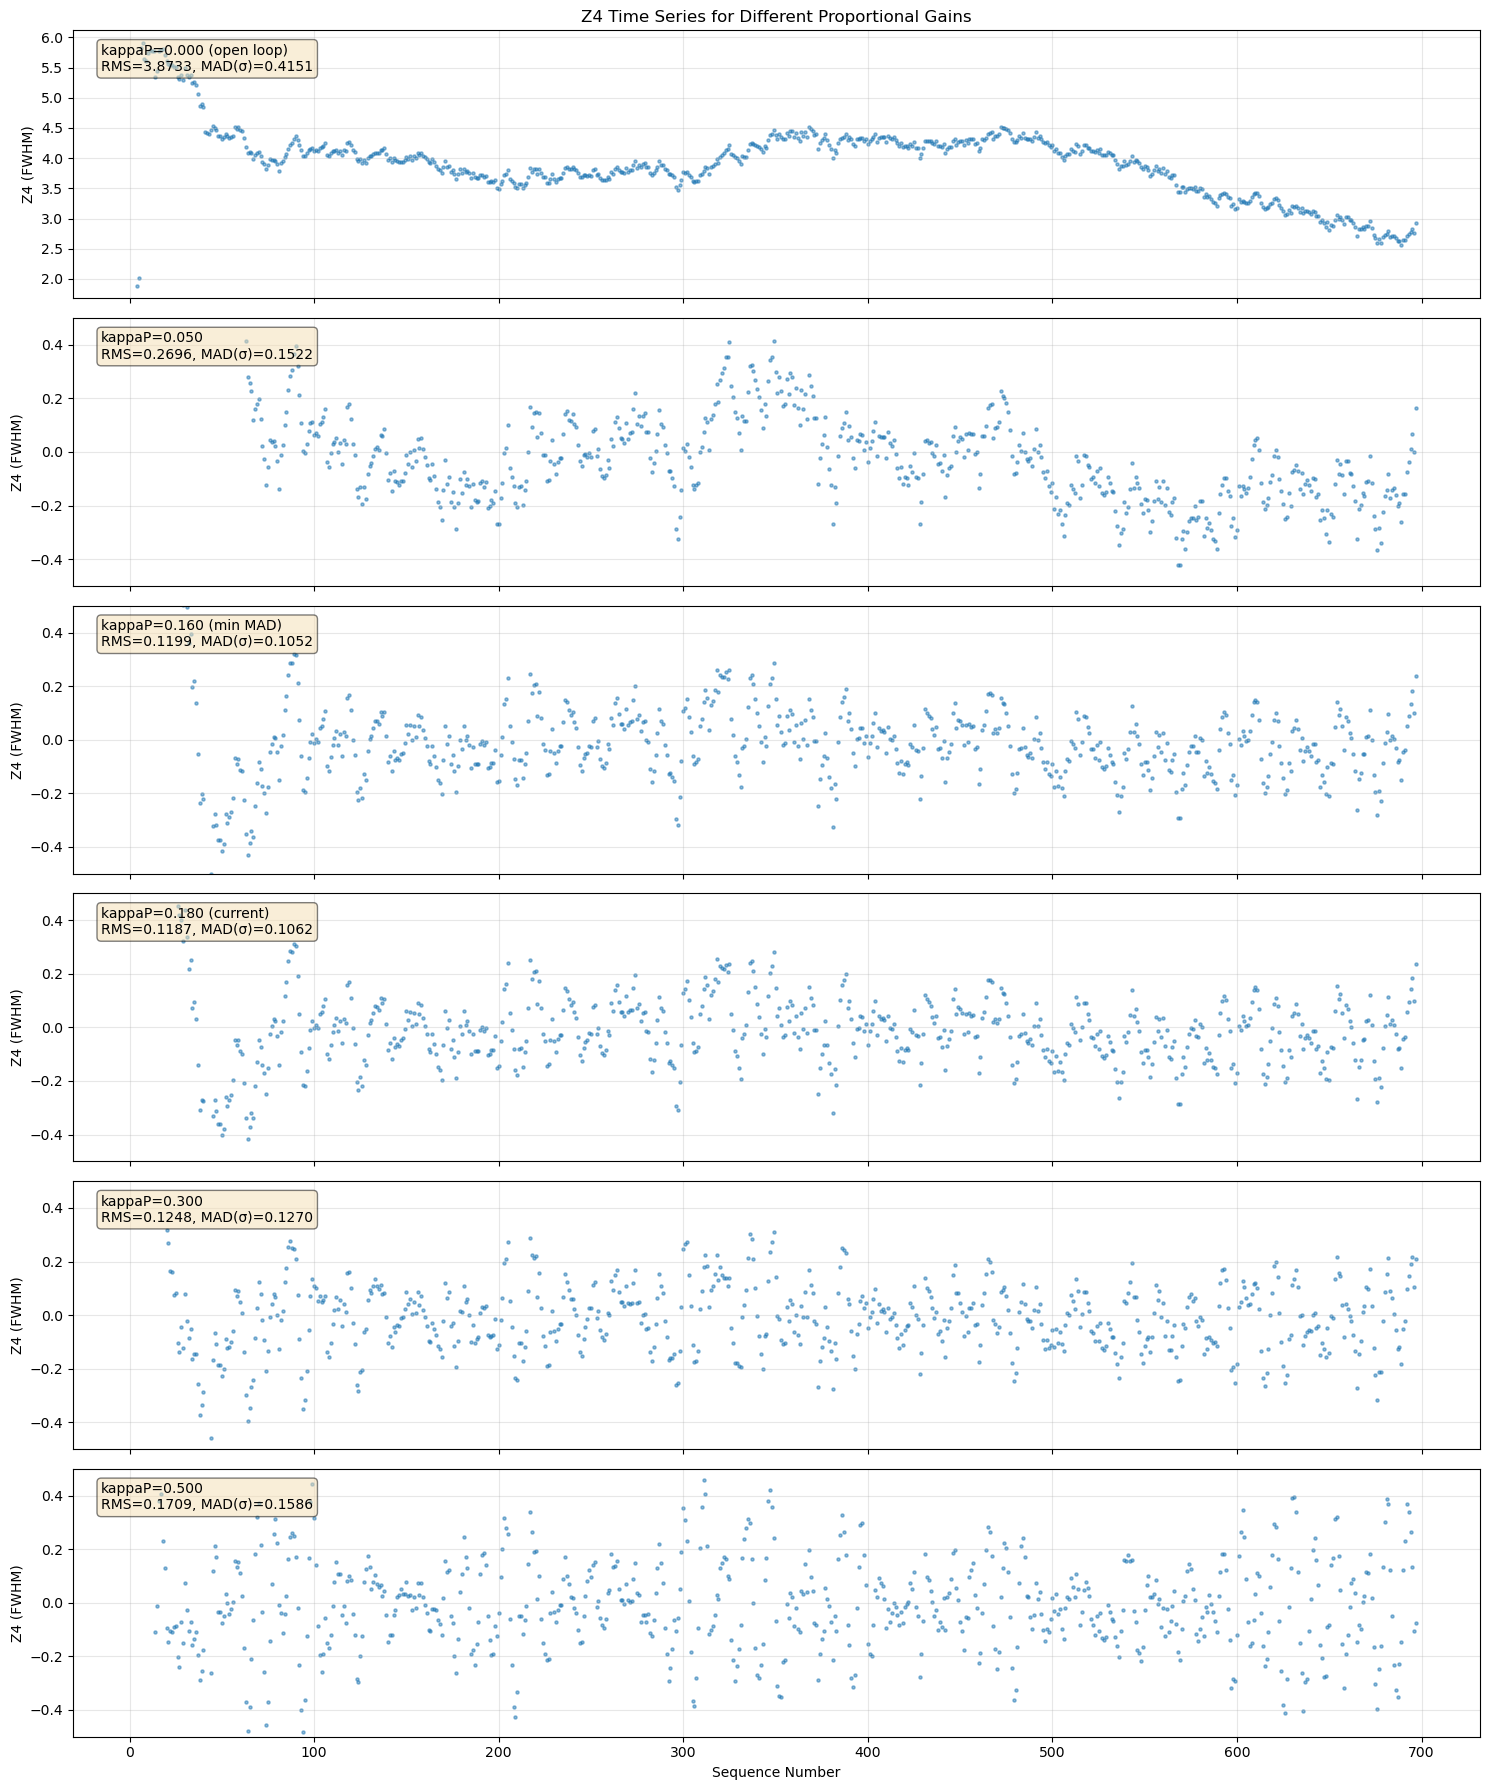

In [29]:
# Compare Z4 time series for selected gains
selected_gains = [0.0, 0.05, kappaP_values[min_mad_idx], kappaP, 0.30, 0.50]
labels_sel = [f'kappaP={kp:.3f}' + (' (open loop)' if kp == 0 else
              ' (min MAD)' if kp == kappaP_values[min_mad_idx] else
              ' (current)' if kp == kappaP else '')
              for kp in selected_gains]

f, ax = plt.subplots(len(selected_gains), 1, figsize=(15, 3*len(selected_gains)),
                     sharex=True)

for j, (kp, lab) in enumerate(zip(selected_gains, labels_sel)):
    z4_sim, _ = simulate_closed_loop(z4_disturbance, vmode5_fwhm[0], seqs,
                                      seq_num_corr, kp)
    z4_qual = z4_sim[quality_idx]
    rms = np.sqrt(np.mean(z4_qual**2))
    mad = median_abs_deviation(z4_qual, scale='normal')
    
    ax[j].scatter(seqs, z4_sim, s=5, alpha=0.5)
    ax[j].set_ylabel('Z4 (FWHM)')
    ax[j].grid(True, alpha=0.3)
    ax[j].text(0.02, 0.95, f'{lab}\nRMS={rms:.4f}, MAD(σ)={mad:.4f}',
               transform=ax[j].transAxes, va='top', fontsize=10,
               bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    # Use same ylim for all panels except open loop
    if kp > 0:
        ax[j].set_ylim(-0.5, 0.5)

ax[-1].set_xlabel('Sequence Number')
ax[0].set_title('Z4 Time Series for Different Proportional Gains')
plt.tight_layout()

## Smith Predictor and Kalman Filter

Compare three control strategies:
1. **Standard PID** — acts on delayed measurement directly
2. **Smith Predictor** — compensates for dead time by predicting current z4
3. **Kalman Filter** — constant-velocity disturbance model with optimal state estimation

In [30]:
# Estimate Kalman Filter noise parameters from disturbance data
# sigma_process: acceleration noise (2nd difference of disturbance)
# sigma_meas: measurement noise (from validation residual)

d_qual = z4_disturbance[quality_idx]
seqs_qual = seqs[quality_idx]

# First differences (velocity of disturbance)
first_diff = np.diff(d_qual)
# Second differences (acceleration of disturbance)
second_diff = np.diff(first_diff)

sigma_process_est = median_abs_deviation(second_diff, scale='normal')
sigma_meas_est = median_abs_deviation(residual_qual, scale='normal')

print(f'Kalman Filter noise parameter estimates (from quality data):')
print(f'  sigma_process (MAD of 2nd diff): {sigma_process_est:.6f}')
print(f'  sigma_meas (MAD of residual):    {sigma_meas_est:.6f}')
print(f'  Ratio process/meas:              {sigma_process_est/sigma_meas_est:.2f}')
print()

# Also show disturbance statistics
print(f'Disturbance statistics (quality data, N={len(d_qual)}):')
print(f'  RMS:    {np.sqrt(np.mean(d_qual**2)):.4f}')
print(f'  MAD(σ): {median_abs_deviation(d_qual, scale="normal"):.4f}')
print(f'  1st diff MAD(σ): {median_abs_deviation(first_diff, scale="normal"):.4f}')
print(f'  2nd diff MAD(σ): {sigma_process_est:.4f}')

Kalman Filter noise parameter estimates (from quality data):
  sigma_process (MAD of 2nd diff): 0.091425
  sigma_meas (MAD of residual):    0.004812
  Ratio process/meas:              19.00

Disturbance statistics (quality data, N=627):
  RMS:    3.8733
  MAD(σ): 0.4151
  1st diff MAD(σ): 0.0683
  2nd diff MAD(σ): 0.0914


Controller comparison (quality data, N=627):
Controller            Opt kP (MAD)  Min MAD(σ)  Opt kP (RMS)     Min RMS
────────────────────  ────────────  ──────────  ────────────  ──────────
Standard PID                 0.160      0.1052         0.195      0.1185
Smith Predictor              0.340      0.0999         0.505      0.1079
Kalman Filter                0.230      0.1069         0.290      0.1219

At current kappaP=0.18:
  Standard PID:   MAD=0.1062  RMS=0.1187
  Smith Predictor: MAD=0.1075  RMS=0.1209
  Kalman Filter:   MAD=0.1134  RMS=0.1246


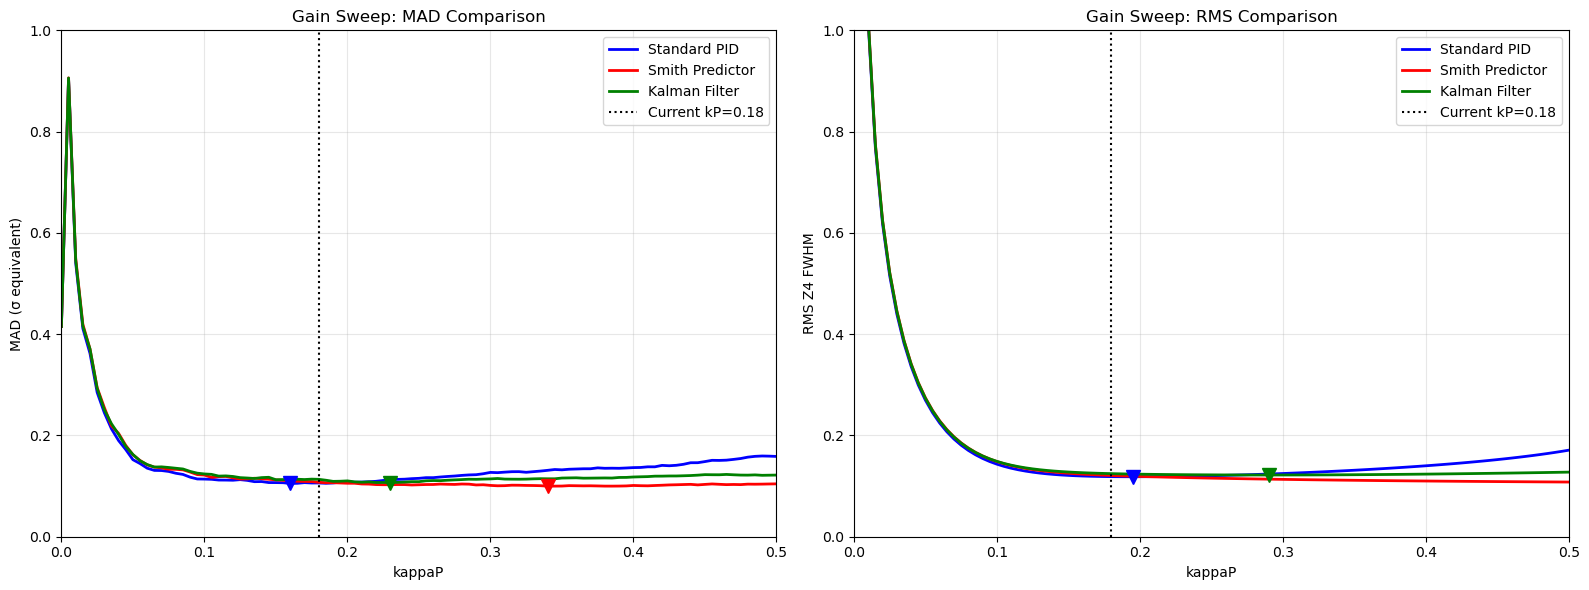

In [31]:
# Gain sweep comparison: Standard PID vs Smith Predictor vs Kalman Filter
# Evaluate MAD performance on quality data

kappaP_values_ctrl = np.arange(0.0, 0.51, 0.005)
n_gains = len(kappaP_values_ctrl)

mad_pid = np.zeros(n_gains)
mad_smith = np.zeros(n_gains)
mad_kalman = np.zeros(n_gains)
rms_pid = np.zeros(n_gains)
rms_smith = np.zeros(n_gains)
rms_kalman = np.zeros(n_gains)

for j, kp in enumerate(kappaP_values_ctrl):
    # Standard PID
    z4_sim, _ = simulate_closed_loop(z4_disturbance, vmode5_fwhm[0], seqs,
                                      seq_num_corr, kp)
    z4_qual = z4_sim[quality_idx]
    mad_pid[j] = median_abs_deviation(z4_qual, scale='normal')
    rms_pid[j] = np.sqrt(np.mean(z4_qual**2))
    
    # Smith Predictor
    z4_sim_sp, _ = simulate_smith_predictor(z4_disturbance, vmode5_fwhm[0], seqs,
                                             seq_num_corr, kp)
    z4_qual_sp = z4_sim_sp[quality_idx]
    mad_smith[j] = median_abs_deviation(z4_qual_sp, scale='normal')
    rms_smith[j] = np.sqrt(np.mean(z4_qual_sp**2))
    
    # Kalman Filter
    z4_sim_kf, _ = simulate_kalman_filter(z4_disturbance, vmode5_fwhm[0], seqs,
                                           seq_num_corr, kp,
                                           sigma_process=sigma_process_est,
                                           sigma_meas=sigma_meas_est)
    z4_qual_kf = z4_sim_kf[quality_idx]
    mad_kalman[j] = median_abs_deviation(z4_qual_kf, scale='normal')
    rms_kalman[j] = np.sqrt(np.mean(z4_qual_kf**2))

# Find optima
opt_pid_mad = np.argmin(mad_pid)
opt_smith_mad = np.argmin(mad_smith)
opt_kalman_mad = np.argmin(mad_kalman)
opt_pid_rms = np.argmin(rms_pid)
opt_smith_rms = np.argmin(rms_smith)
opt_kalman_rms = np.argmin(rms_kalman)

# Plot MAD comparison
f, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
ax.plot(kappaP_values_ctrl, mad_pid, 'b-', linewidth=2, label='Standard PID')
ax.plot(kappaP_values_ctrl, mad_smith, 'r-', linewidth=2, label='Smith Predictor')
ax.plot(kappaP_values_ctrl, mad_kalman, 'g-', linewidth=2, label='Kalman Filter')
ax.axvline(kappaP, color='black', linestyle=':', linewidth=1.5, label=f'Current kP={kappaP}')
ax.plot(kappaP_values_ctrl[opt_pid_mad], mad_pid[opt_pid_mad], 'bv', markersize=10)
ax.plot(kappaP_values_ctrl[opt_smith_mad], mad_smith[opt_smith_mad], 'rv', markersize=10)
ax.plot(kappaP_values_ctrl[opt_kalman_mad], mad_kalman[opt_kalman_mad], 'gv', markersize=10)
ax.set_xlabel('kappaP')
ax.set_ylabel('MAD (σ equivalent)')
ax.set_title('Gain Sweep: MAD Comparison')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 0.5)
ax.set_ylim(0, 1)

ax = axes[1]
ax.plot(kappaP_values_ctrl, rms_pid, 'b-', linewidth=2, label='Standard PID')
ax.plot(kappaP_values_ctrl, rms_smith, 'r-', linewidth=2, label='Smith Predictor')
ax.plot(kappaP_values_ctrl, rms_kalman, 'g-', linewidth=2, label='Kalman Filter')
ax.axvline(kappaP, color='black', linestyle=':', linewidth=1.5, label=f'Current kP={kappaP}')
ax.plot(kappaP_values_ctrl[opt_pid_rms], rms_pid[opt_pid_rms], 'bv', markersize=10)
ax.plot(kappaP_values_ctrl[opt_smith_rms], rms_smith[opt_smith_rms], 'rv', markersize=10)
ax.plot(kappaP_values_ctrl[opt_kalman_rms], rms_kalman[opt_kalman_rms], 'gv', markersize=10)
ax.set_xlabel('kappaP')
ax.set_ylabel('RMS Z4 FWHM')
ax.set_title('Gain Sweep: RMS Comparison')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 0.5)
ax.set_ylim(0, 1)

plt.tight_layout()

# Print summary table
print(f'Controller comparison (quality data, N={len(quality_idx)}):')
print(f'{"Controller":<20s}  {"Opt kP (MAD)":>12s}  {"Min MAD(σ)":>10s}  {"Opt kP (RMS)":>12s}  {"Min RMS":>10s}')
print(f'{"─"*20}  {"─"*12}  {"─"*10}  {"─"*12}  {"─"*10}')
for name, mad_arr, rms_arr, oi_mad, oi_rms in [
    ('Standard PID', mad_pid, rms_pid, opt_pid_mad, opt_pid_rms),
    ('Smith Predictor', mad_smith, rms_smith, opt_smith_mad, opt_smith_rms),
    ('Kalman Filter', mad_kalman, rms_kalman, opt_kalman_mad, opt_kalman_rms),
]:
    print(f'{name:<20s}  {kappaP_values_ctrl[oi_mad]:12.3f}  {mad_arr[oi_mad]:10.4f}  {kappaP_values_ctrl[oi_rms]:12.3f}  {rms_arr[oi_rms]:10.4f}')

# Also show improvement at current gain
print(f'''
At current kappaP={kappaP}:
  Standard PID:   MAD={mad_pid[np.argmin(np.abs(kappaP_values_ctrl - kappaP))]:.4f}  RMS={rms_pid[np.argmin(np.abs(kappaP_values_ctrl - kappaP))]:.4f}
  Smith Predictor: MAD={mad_smith[np.argmin(np.abs(kappaP_values_ctrl - kappaP))]:.4f}  RMS={rms_smith[np.argmin(np.abs(kappaP_values_ctrl - kappaP))]:.4f}
  Kalman Filter:   MAD={mad_kalman[np.argmin(np.abs(kappaP_values_ctrl - kappaP))]:.4f}  RMS={rms_kalman[np.argmin(np.abs(kappaP_values_ctrl - kappaP))]:.4f}''')

Time series at MAD-optimal gains (quality data, N=627):
  Standard PID        : kP=0.160, RMS=0.1199, MAD(σ)=0.1052
  Smith Predictor     : kP=0.340, RMS=0.1118, MAD(σ)=0.0999
  Kalman Filter       : kP=0.230, RMS=0.1225, MAD(σ)=0.1069


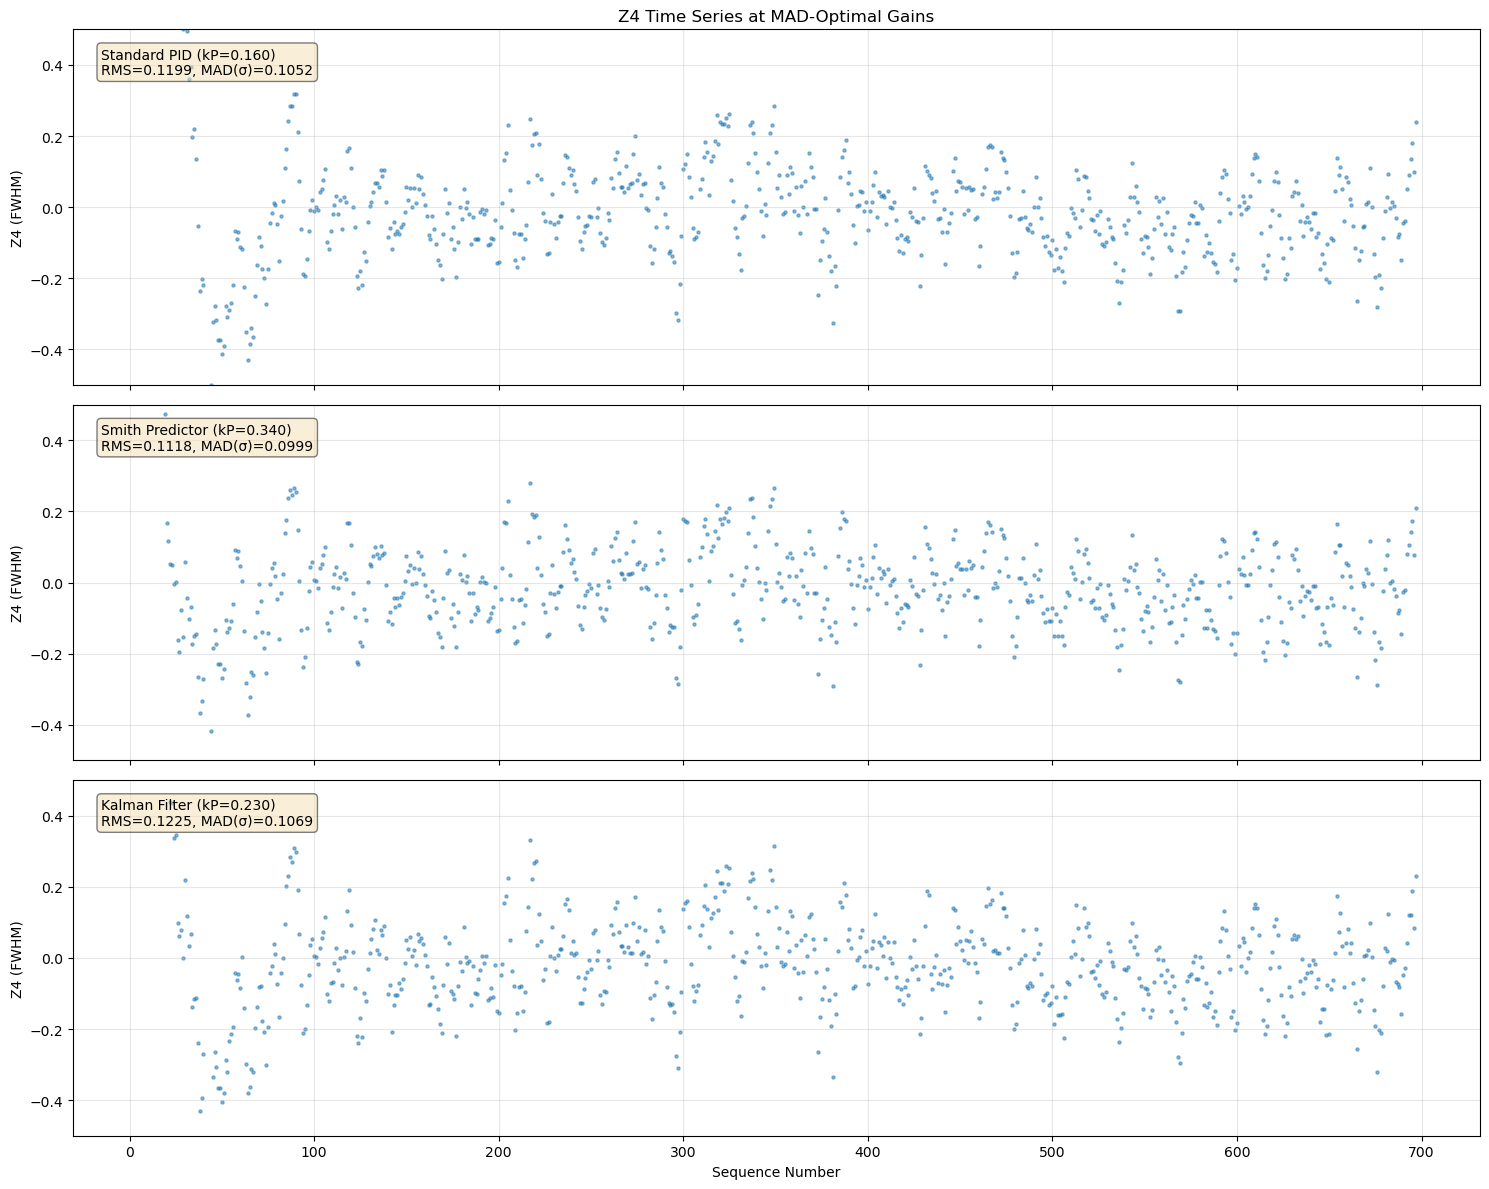

In [32]:
# Time series comparison at MAD-optimal gains for each controller

controllers = [
    ('Standard PID', simulate_closed_loop, kappaP_values_ctrl[opt_pid_mad], {}),
    ('Smith Predictor', simulate_smith_predictor, kappaP_values_ctrl[opt_smith_mad], {}),
    ('Kalman Filter', simulate_kalman_filter, kappaP_values_ctrl[opt_kalman_mad],
     {'sigma_process': sigma_process_est, 'sigma_meas': sigma_meas_est}),
]

f, axes = plt.subplots(len(controllers), 1, figsize=(15, 4*len(controllers)),
                       sharex=True)

for j, (name, sim_func, kp_opt, extra_kwargs) in enumerate(controllers):
    z4_sim, v5_sim = sim_func(z4_disturbance, vmode5_fwhm[0], seqs,
                               seq_num_corr, kp_opt, **extra_kwargs)
    z4_qual = z4_sim[quality_idx]
    rms = np.sqrt(np.mean(z4_qual**2))
    mad = median_abs_deviation(z4_qual, scale='normal')
    
    axes[j].scatter(seqs, z4_sim, s=5, alpha=0.5)
    axes[j].set_ylabel('Z4 (FWHM)')
    axes[j].grid(True, alpha=0.3)
    axes[j].set_ylim(-0.5, 0.5)
    axes[j].text(0.02, 0.95,
                 f'{name} (kP={kp_opt:.3f})\nRMS={rms:.4f}, MAD(σ)={mad:.4f}',
                 transform=axes[j].transAxes, va='top', fontsize=10,
                 bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

axes[-1].set_xlabel('Sequence Number')
axes[0].set_title('Z4 Time Series at MAD-Optimal Gains')
plt.tight_layout()

# Print summary
print(f'Time series at MAD-optimal gains (quality data, N={len(quality_idx)}):')
for name, sim_func, kp_opt, extra_kwargs in controllers:
    z4_sim, _ = sim_func(z4_disturbance, vmode5_fwhm[0], seqs,
                          seq_num_corr, kp_opt, **extra_kwargs)
    z4_qual = z4_sim[quality_idx]
    rms = np.sqrt(np.mean(z4_qual**2))
    mad = median_abs_deviation(z4_qual, scale='normal')
    print(f'  {name:<20s}: kP={kp_opt:.3f}, RMS={rms:.4f}, MAD(σ)={mad:.4f}')

## Minimum Variance Control and Dead Time Analysis

The Smith Predictor and Kalman Filter provided only modest improvement because they
don't help predict the disturbance — they only account for known control actions.

**Minimum Variance Control (MVC)** uses an AR model of the disturbance to predict
d-steps ahead and cancel the predicted value. The prediction error gives the
**theoretical lower bound** — the minimum achievable Z4 for a given dead time.

We also simulate what standard PID would achieve with **reduced dead time** (lag=2, lag=1).

AR model order selection (minimizing 3-step-ahead prediction MAD):
  Best order: AR(20)
  AR coefficients: [ 0.8537  0.2034 -0.1406 -0.0841  0.0302  0.028   0.0925 -0.0089 -0.0533
  0.0462  0.048   0.0057  0.0304 -0.0377 -0.0019  0.0304 -0.0126  0.0107
  0.0049 -0.0457]

Theoretical lower bounds (AR(20) prediction error):
   Dead time      MAD(σ)         RMS    vs PID@d=3
  ──────────  ──────────  ──────────  ────────────
  d=       1      0.0642      0.0615        61.1%
  d=       2      0.0854      0.0807        81.2%
  d=       3      0.0968      0.0989        92.0%
  d=       4      0.1087      0.1111       103.3%
  d=       5      0.1114      0.1187       105.9%

  Current PID (d=3, kP=0.160): MAD(σ) = 0.1052
  Open loop:                         MAD(σ) = 0.4151


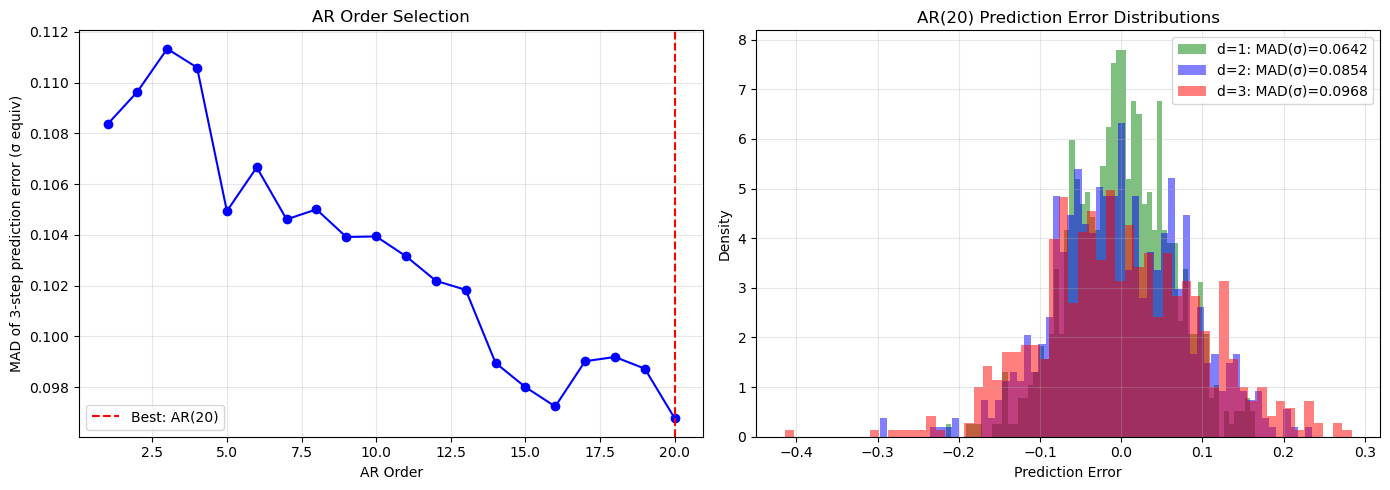

In [33]:
# Fit AR model to disturbance and compute theoretical lower bounds

# Use quality-masked disturbance for fitting
d_qual = z4_disturbance[quality_idx]

# Try AR orders 1-20, select by 3-step-ahead prediction MAD on quality data
ar_orders = np.arange(1, 21)
pred_mad_by_order = np.zeros(len(ar_orders))

for i, p in enumerate(ar_orders):
    coeffs = fit_ar_model(d_qual, p)
    # Compute 3-step-ahead prediction errors
    errors = []
    for k in range(p + 3, len(d_qual)):
        d_pred = ar_predict_ahead(d_qual[:k-3+1], coeffs, 3)
        errors.append(d_qual[k] - d_pred)
    pred_mad_by_order[i] = median_abs_deviation(np.array(errors), scale='normal')

best_order_idx = np.argmin(pred_mad_by_order)
best_order = ar_orders[best_order_idx]
ar_coeffs = fit_ar_model(d_qual, best_order)

print(f'AR model order selection (minimizing 3-step-ahead prediction MAD):')
print(f'  Best order: AR({best_order})')
print(f'  AR coefficients: {np.array2string(ar_coeffs, precision=4, suppress_small=True)}')
print()

# Plot order selection
f, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(ar_orders, pred_mad_by_order, 'bo-')
axes[0].axvline(best_order, color='red', linestyle='--', label=f'Best: AR({best_order})')
axes[0].set_xlabel('AR Order')
axes[0].set_ylabel('MAD of 3-step prediction error (σ equiv)')
axes[0].set_title('AR Order Selection')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Compute theoretical lower bounds for d = 1, 2, 3, 4, 5
dead_times = [1, 2, 3, 4, 5]
pred_errors = {}
pred_mad_vals = {}
pred_rms_vals = {}

for d in dead_times:
    errors = []
    for k in range(best_order + d, len(d_qual)):
        d_pred = ar_predict_ahead(d_qual[:k-d+1], ar_coeffs, d)
        errors.append(d_qual[k] - d_pred)
    errors = np.array(errors)
    pred_errors[d] = errors
    pred_mad_vals[d] = median_abs_deviation(errors, scale='normal')
    pred_rms_vals[d] = np.sqrt(np.mean(errors**2))

# Plot prediction error distributions
colors = ['green', 'blue', 'red', 'orange', 'purple']
for i, d in enumerate(dead_times[:3]):
    axes[1].hist(pred_errors[d], bins=60, alpha=0.5, density=True,
                 label=f'd={d}: MAD(σ)={pred_mad_vals[d]:.4f}', color=colors[i])
axes[1].set_xlabel('Prediction Error')
axes[1].set_ylabel('Density')
axes[1].set_title(f'AR({best_order}) Prediction Error Distributions')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()

# Print theoretical lower bounds
print(f'Theoretical lower bounds (AR({best_order}) prediction error):')
print(f'  {"Dead time":>10s}  {"MAD(σ)":>10s}  {"RMS":>10s}  {"vs PID@d=3":>12s}')
print(f'  {"─"*10}  {"─"*10}  {"─"*10}  {"─"*12}')
pid_mad_current = mad_z4[min_mad_idx]  # from cell 46 gain sweep
for d in dead_times:
    ratio = pred_mad_vals[d] / pid_mad_current
    print(f'  d={d:>8d}  {pred_mad_vals[d]:10.4f}  {pred_rms_vals[d]:10.4f}  {ratio:11.1%}')
print(f'\n  Current PID (d=3, kP={kappaP_values[min_mad_idx]:.3f}): MAD(σ) = {pid_mad_current:.4f}')
print(f'  Open loop:                         MAD(σ) = {mad_z4[0]:.4f}')

Dead time comparison (quality data, N=627):
Controller                Opt kP      MAD(σ)         RMS    AR floor    vs PID d=3
──────────────────────  ────────  ──────────  ──────────  ──────────  ────────────
PID d=3 (current)          0.160      0.1052      0.1199      0.0968       100.0%
MVC d=3                     n/a       0.0933      0.0988      0.0968        88.7%
PID d=2                    0.250      0.0946      0.1014      0.0854        90.0%
MVC d=2                     n/a       0.0825      0.0818      0.0854        78.5%
PID d=1                    0.845      0.0643      0.0633      0.0642        61.1%
MVC d=1                     n/a       0.0628      0.0609      0.0642        59.7%


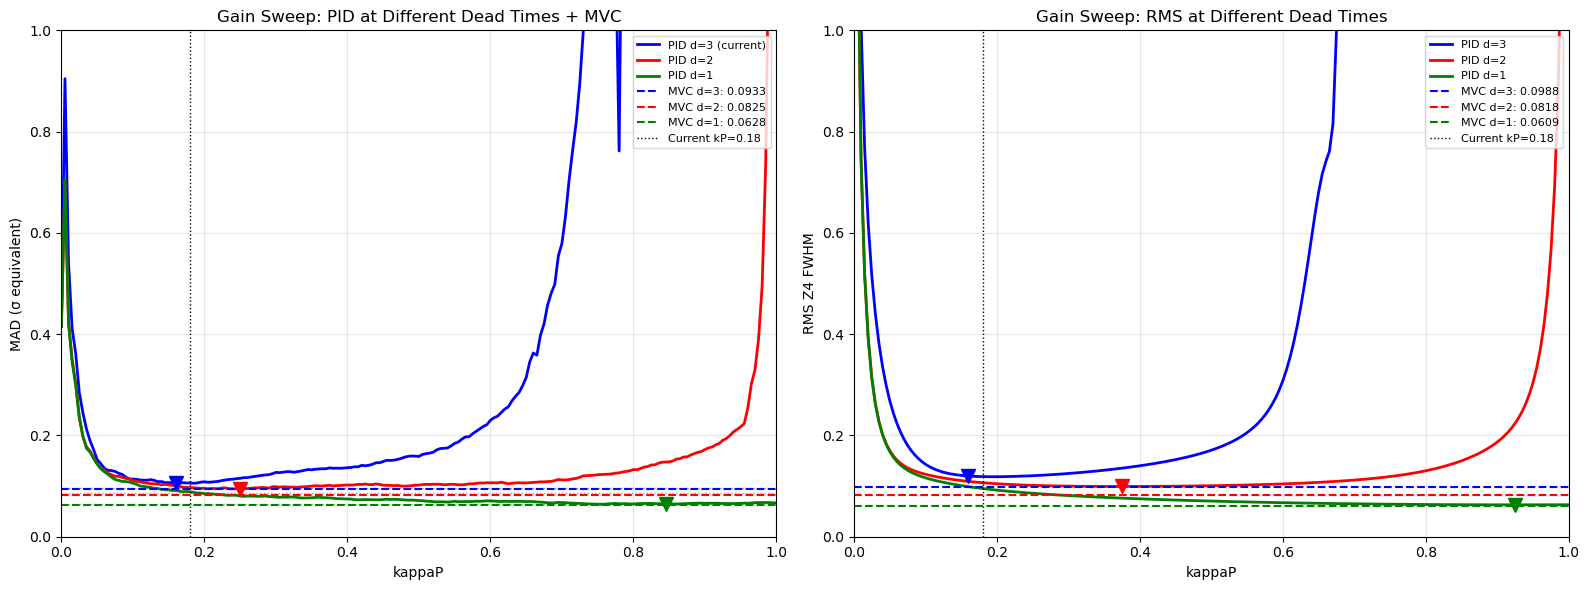

In [34]:
# Gain sweep: PID with reduced dead time + MVC comparison

# Build modified seq_num_corr arrays for reduced dead time
n_imgs = len(seqs)

seq_num_corr_lag1 = np.full(n_imgs, -1.0)
seq_num_corr_lag2 = np.full(n_imgs, -1.0)
for k in range(1, n_imgs):
    seq_num_corr_lag1[k] = seqs[k - 1]
for k in range(2, n_imgs):
    seq_num_corr_lag2[k] = seqs[k - 2]

# Gain sweep for PID at each dead time
kappaP_values_dt = np.arange(0.0, 1.01, 0.005)
n_gains = len(kappaP_values_dt)

mad_pid_d3 = np.zeros(n_gains)
mad_pid_d2 = np.zeros(n_gains)
mad_pid_d1 = np.zeros(n_gains)
rms_pid_d3 = np.zeros(n_gains)
rms_pid_d2 = np.zeros(n_gains)
rms_pid_d1 = np.zeros(n_gains)

for j, kp in enumerate(kappaP_values_dt):
    # PID at d=3 (original)
    z4_sim, _ = simulate_closed_loop(z4_disturbance, vmode5_fwhm[0], seqs,
                                      seq_num_corr, kp)
    z4_q = z4_sim[quality_idx]
    mad_pid_d3[j] = median_abs_deviation(z4_q, scale='normal')
    rms_pid_d3[j] = np.sqrt(np.mean(z4_q**2))
    
    # PID at d=2
    z4_sim, _ = simulate_closed_loop(z4_disturbance, vmode5_fwhm[0], seqs,
                                      seq_num_corr_lag2, kp)
    z4_q = z4_sim[quality_idx]
    mad_pid_d2[j] = median_abs_deviation(z4_q, scale='normal')
    rms_pid_d2[j] = np.sqrt(np.mean(z4_q**2))
    
    # PID at d=1
    z4_sim, _ = simulate_closed_loop(z4_disturbance, vmode5_fwhm[0], seqs,
                                      seq_num_corr_lag1, kp)
    z4_q = z4_sim[quality_idx]
    mad_pid_d1[j] = median_abs_deviation(z4_q, scale='normal')
    rms_pid_d1[j] = np.sqrt(np.mean(z4_q**2))

# MVC at d=3 (no gain parameter)
z4_mvc, _ = simulate_mvc(z4_disturbance, vmode5_fwhm[0], seqs, seq_num_corr,
                          ar_coeffs, G=1.0)
z4_mvc_q = z4_mvc[quality_idx]
mad_mvc_d3 = median_abs_deviation(z4_mvc_q, scale='normal')
rms_mvc_d3 = np.sqrt(np.mean(z4_mvc_q**2))

# MVC at d=2 and d=1
z4_mvc2, _ = simulate_mvc(z4_disturbance, vmode5_fwhm[0], seqs, seq_num_corr_lag2,
                           ar_coeffs, G=1.0)
z4_mvc2_q = z4_mvc2[quality_idx]
mad_mvc_d2 = median_abs_deviation(z4_mvc2_q, scale='normal')
rms_mvc_d2 = np.sqrt(np.mean(z4_mvc2_q**2))

z4_mvc1, _ = simulate_mvc(z4_disturbance, vmode5_fwhm[0], seqs, seq_num_corr_lag1,
                           ar_coeffs, G=1.0)
z4_mvc1_q = z4_mvc1[quality_idx]
mad_mvc_d1 = median_abs_deviation(z4_mvc1_q, scale='normal')
rms_mvc_d1 = np.sqrt(np.mean(z4_mvc1_q**2))

# Find optima
opt_d3 = np.argmin(mad_pid_d3)
opt_d2 = np.argmin(mad_pid_d2)
opt_d1 = np.argmin(mad_pid_d1)

# Plot
f, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
ax.plot(kappaP_values_dt, mad_pid_d3, 'b-', linewidth=2, label=f'PID d=3 (current)')
ax.plot(kappaP_values_dt, mad_pid_d2, 'r-', linewidth=2, label=f'PID d=2')
ax.plot(kappaP_values_dt, mad_pid_d1, 'g-', linewidth=2, label=f'PID d=1')
ax.axhline(mad_mvc_d3, color='blue', linestyle='--', linewidth=1.5,
           label=f'MVC d=3: {mad_mvc_d3:.4f}')
ax.axhline(mad_mvc_d2, color='red', linestyle='--', linewidth=1.5,
           label=f'MVC d=2: {mad_mvc_d2:.4f}')
ax.axhline(mad_mvc_d1, color='green', linestyle='--', linewidth=1.5,
           label=f'MVC d=1: {mad_mvc_d1:.4f}')
# Theoretical floors
for d, color in [(1, 'green'), (2, 'red'), (3, 'blue')]:
    ax.axhline(pred_mad_vals[d], color=color, linestyle=':', linewidth=1, alpha=0.5)
ax.plot(kappaP_values_dt[opt_d3], mad_pid_d3[opt_d3], 'bv', markersize=10)
ax.plot(kappaP_values_dt[opt_d2], mad_pid_d2[opt_d2], 'rv', markersize=10)
ax.plot(kappaP_values_dt[opt_d1], mad_pid_d1[opt_d1], 'gv', markersize=10)
ax.axvline(kappaP, color='black', linestyle=':', linewidth=1, label=f'Current kP={kappaP}')
ax.set_xlabel('kappaP')
ax.set_ylabel('MAD (σ equivalent)')
ax.set_title('Gain Sweep: PID at Different Dead Times + MVC')
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 1.0)
ax.set_ylim(0, 1)

ax = axes[1]
ax.plot(kappaP_values_dt, rms_pid_d3, 'b-', linewidth=2, label=f'PID d=3')
ax.plot(kappaP_values_dt, rms_pid_d2, 'r-', linewidth=2, label=f'PID d=2')
ax.plot(kappaP_values_dt, rms_pid_d1, 'g-', linewidth=2, label=f'PID d=1')
ax.axhline(rms_mvc_d3, color='blue', linestyle='--', linewidth=1.5,
           label=f'MVC d=3: {rms_mvc_d3:.4f}')
ax.axhline(rms_mvc_d2, color='red', linestyle='--', linewidth=1.5,
           label=f'MVC d=2: {rms_mvc_d2:.4f}')
ax.axhline(rms_mvc_d1, color='green', linestyle='--', linewidth=1.5,
           label=f'MVC d=1: {rms_mvc_d1:.4f}')
ax.plot(kappaP_values_dt[opt_d3], rms_pid_d3[opt_d3], 'bv', markersize=10)
ax.plot(kappaP_values_dt[np.argmin(rms_pid_d2)], rms_pid_d2[np.argmin(rms_pid_d2)], 'rv', markersize=10)
ax.plot(kappaP_values_dt[np.argmin(rms_pid_d1)], rms_pid_d1[np.argmin(rms_pid_d1)], 'gv', markersize=10)
ax.axvline(kappaP, color='black', linestyle=':', linewidth=1, label=f'Current kP={kappaP}')
ax.set_xlabel('kappaP')
ax.set_ylabel('RMS Z4 FWHM')
ax.set_title('Gain Sweep: RMS at Different Dead Times')
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 1.0)
ax.set_ylim(0, 1)
plt.tight_layout()

# Summary table
print(f'Dead time comparison (quality data, N={len(quality_idx)}):')
print(f'{"Controller":<22s}  {"Opt kP":>8s}  {"MAD(σ)":>10s}  {"RMS":>10s}  {"AR floor":>10s}  {"vs PID d=3":>12s}')
print(f'{"─"*22}  {"─"*8}  {"─"*10}  {"─"*10}  {"─"*10}  {"─"*12}')
rows = [
    ('PID d=3 (current)', kappaP_values_dt[opt_d3], mad_pid_d3[opt_d3], rms_pid_d3[opt_d3], pred_mad_vals[3]),
    ('MVC d=3', None, mad_mvc_d3, rms_mvc_d3, pred_mad_vals[3]),
    ('PID d=2', kappaP_values_dt[opt_d2], mad_pid_d2[opt_d2], rms_pid_d2[opt_d2], pred_mad_vals[2]),
    ('MVC d=2', None, mad_mvc_d2, rms_mvc_d2, pred_mad_vals[2]),
    ('PID d=1', kappaP_values_dt[opt_d1], mad_pid_d1[opt_d1], rms_pid_d1[opt_d1], pred_mad_vals[1]),
    ('MVC d=1', None, mad_mvc_d1, rms_mvc_d1, pred_mad_vals[1]),
]
for name, kp, mad_val, rms_val, floor_val in rows:
    kp_str = f'{kp:.3f}' if kp is not None else '  n/a '
    improvement = mad_val / mad_pid_d3[opt_d3]
    print(f'{name:<22s}  {kp_str:>8s}  {mad_val:10.4f}  {rms_val:10.4f}  {floor_val:10.4f}  {improvement:11.1%}')


Time series summary at optimal settings (quality data, N=627):
Controller                    kP         RMS      MAD(σ)
──────────────────────  ────────  ──────────  ──────────
PID d=3 (current)          0.160      0.1199      0.1052
MVC d=3                     n/a       0.0988      0.0933
PID d=2                    0.250      0.1014      0.0946
MVC d=2                     n/a       0.0818      0.0825
PID d=1                    0.845      0.0633      0.0643
MVC d=1                     n/a       0.0609      0.0628


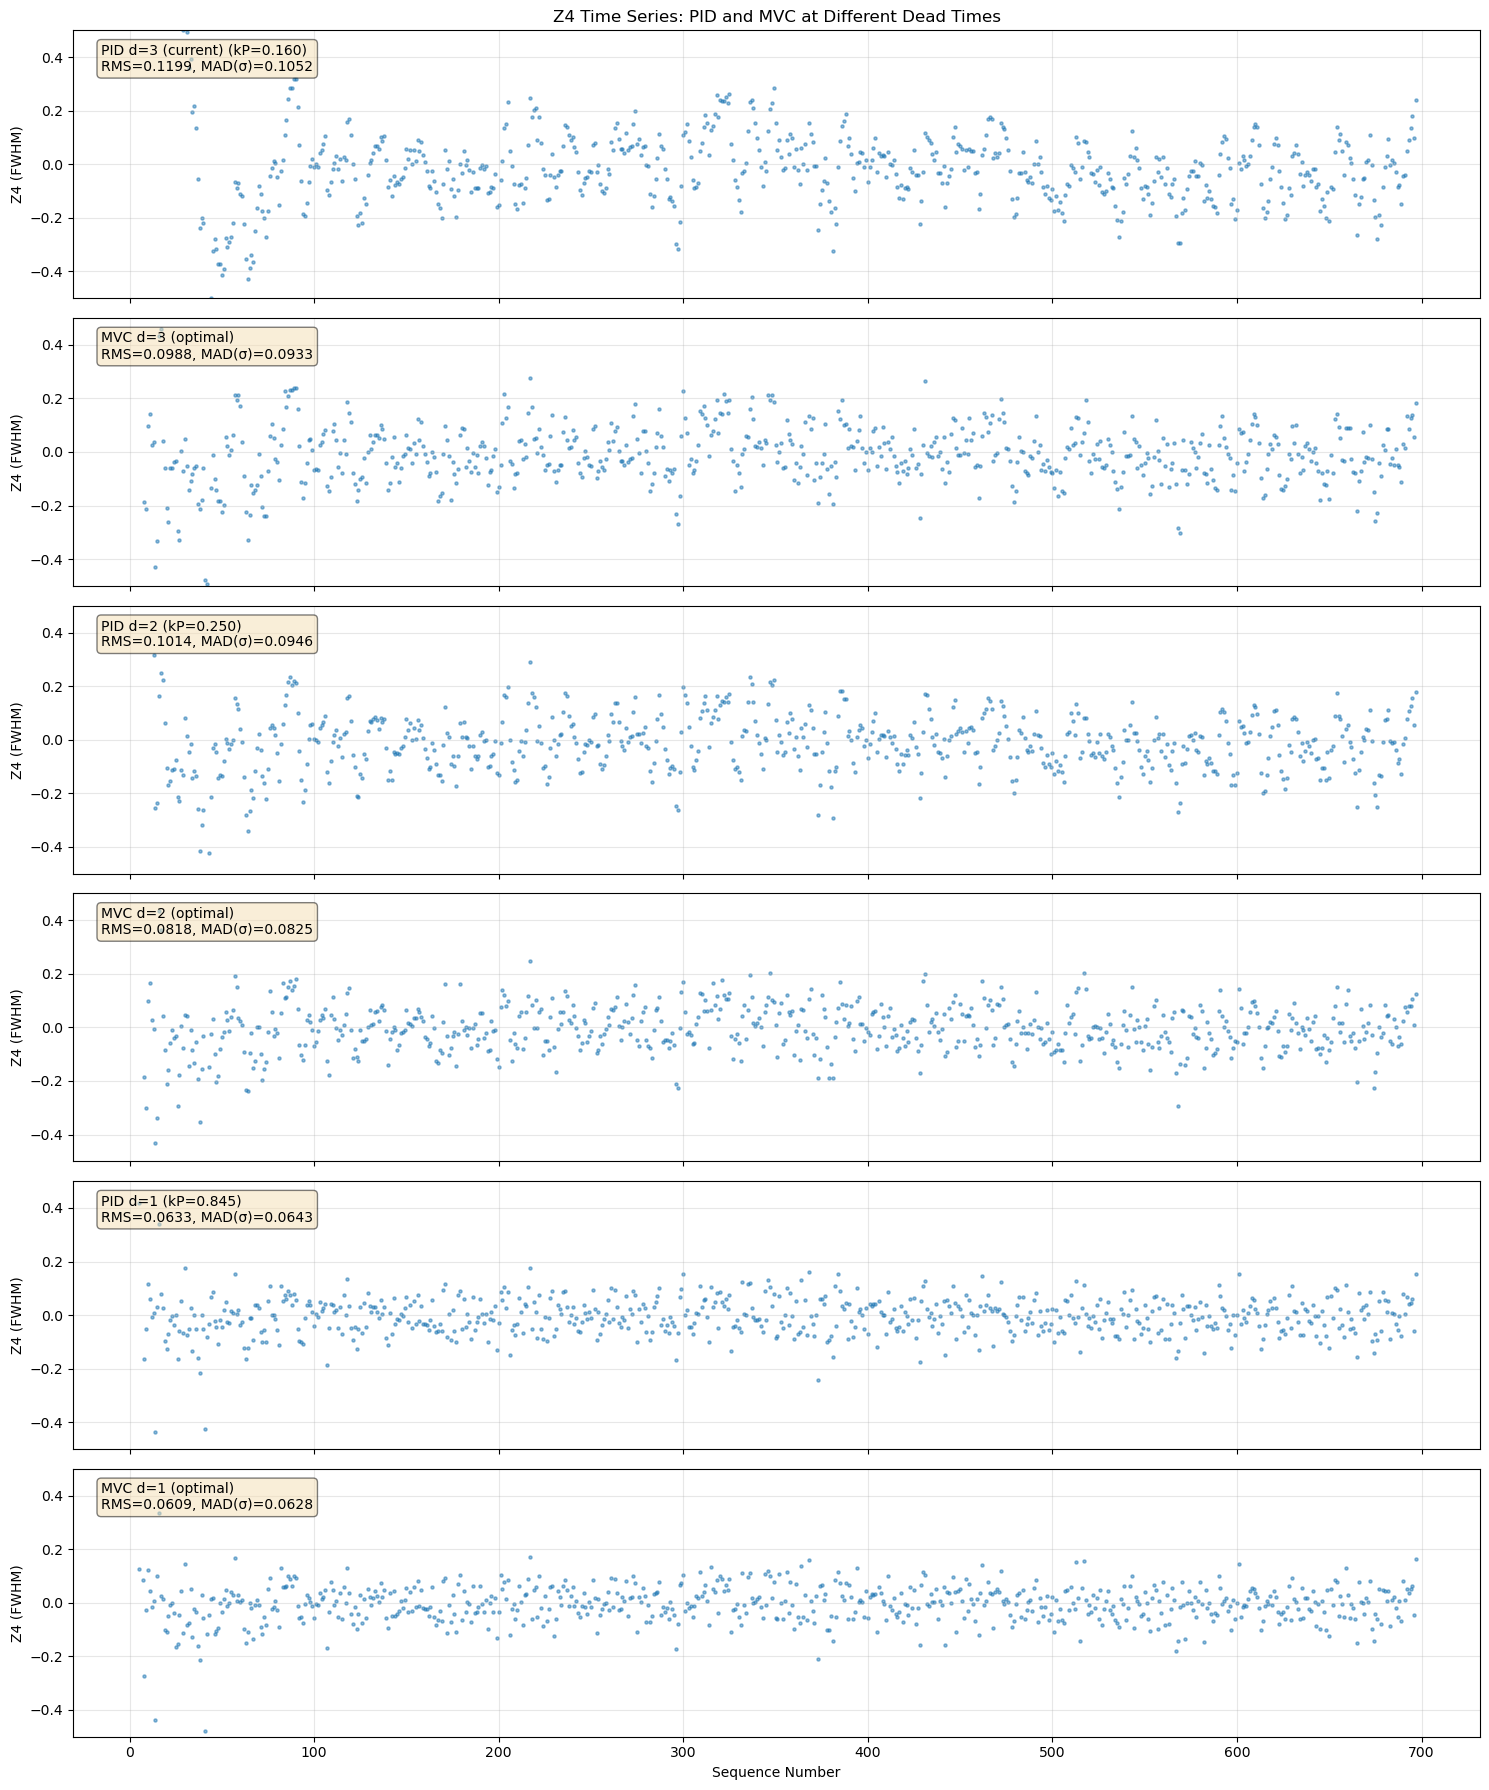

In [35]:
# Time series comparison at optimal settings

controllers_dt = [
    ('PID d=3 (current)', simulate_closed_loop, kappaP_values_dt[opt_d3], seq_num_corr, {}),
    ('MVC d=3', simulate_mvc, None, seq_num_corr, {'ar_coeffs': ar_coeffs}),
    ('PID d=2', simulate_closed_loop, kappaP_values_dt[opt_d2], seq_num_corr_lag2, {}),
    ('MVC d=2', simulate_mvc, None, seq_num_corr_lag2, {'ar_coeffs': ar_coeffs}),
    ('PID d=1', simulate_closed_loop, kappaP_values_dt[opt_d1], seq_num_corr_lag1, {}),
    ('MVC d=1', simulate_mvc, None, seq_num_corr_lag1, {'ar_coeffs': ar_coeffs}),
]

f, axes = plt.subplots(len(controllers_dt), 1,
                       figsize=(15, 3*len(controllers_dt)), sharex=True)

for j, (name, sim_func, kp, snc, extra_kwargs) in enumerate(controllers_dt):
    if kp is not None:
        z4_sim, _ = sim_func(z4_disturbance, vmode5_fwhm[0], seqs, snc, kp,
                              **extra_kwargs)
    else:
        z4_sim, _ = sim_func(z4_disturbance, vmode5_fwhm[0], seqs, snc,
                              **extra_kwargs)
    z4_q = z4_sim[quality_idx]
    rms = np.sqrt(np.mean(z4_q**2))
    mad = median_abs_deviation(z4_q, scale='normal')
    
    axes[j].scatter(seqs, z4_sim, s=5, alpha=0.5)
    axes[j].set_ylabel('Z4 (FWHM)')
    axes[j].grid(True, alpha=0.3)
    axes[j].set_ylim(-0.5, 0.5)
    kp_str = f'kP={kp:.3f}' if kp is not None else 'optimal'
    axes[j].text(0.02, 0.95,
                 f'{name} ({kp_str})\nRMS={rms:.4f}, MAD(σ)={mad:.4f}',
                 transform=axes[j].transAxes, va='top', fontsize=10,
                 bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

axes[-1].set_xlabel('Sequence Number')
axes[0].set_title('Z4 Time Series: PID and MVC at Different Dead Times')
plt.tight_layout()

# Print summary
print(f'\nTime series summary at optimal settings (quality data, N={len(quality_idx)}):')
print(f'{"Controller":<22s}  {"kP":>8s}  {"RMS":>10s}  {"MAD(σ)":>10s}')
print(f'{"─"*22}  {"─"*8}  {"─"*10}  {"─"*10}')
for name, sim_func, kp, snc, extra_kwargs in controllers_dt:
    if kp is not None:
        z4_sim, _ = sim_func(z4_disturbance, vmode5_fwhm[0], seqs, snc, kp,
                              **extra_kwargs)
    else:
        z4_sim, _ = sim_func(z4_disturbance, vmode5_fwhm[0], seqs, snc,
                              **extra_kwargs)
    z4_q = z4_sim[quality_idx]
    rms = np.sqrt(np.mean(z4_q**2))
    mad = median_abs_deviation(z4_q, scale='normal')
    kp_str = f'{kp:.3f}' if kp is not None else '  n/a '
    print(f'{name:<22s}  {kp_str:>8s}  {rms:10.4f}  {mad:10.4f}')

## Summary

In [36]:
# === Summary Table 1: Theoretical Lower Bounds ===
print(f'Table 1: Theoretical Lower Bounds — AR({best_order}) Prediction Error')
print(f'  (Minimum achievable Z4 MAD for any causal controller at given dead time)')
print()
print(f'  {"Dead time":>10s}  {"MAD(σ) floor":>12s}  {"RMS floor":>12s}  {"vs PID d=3":>12s}')
print(f'  {"─"*10}  {"─"*12}  {"─"*12}  {"─"*12}')
pid_d3_ref = mad_pid_d3[opt_d3]
for d in [1, 2, 3, 4, 5]:
    ratio = pred_mad_vals[d] / pid_d3_ref
    print(f'  d={d:>8d}  {pred_mad_vals[d]:12.4f}  {pred_rms_vals[d]:12.4f}  {ratio:11.1%}')
print(f'\n  Reference: PID d=3 optimal MAD(σ) = {pid_d3_ref:.4f}')

# === Summary Table 2: Controller Comparison ===
print(f'\n\nTable 2: Controller Comparison (quality data, N={len(quality_idx)})')
print()
print(f'  {"Controller":<24s}  {"Dead time":>9s}  {"Opt kP":>8s}  {"MAD(σ)":>10s}  {"RMS":>10s}  {"AR floor":>10s}  {"vs PID d=3":>12s}')
print(f'  {"─"*24}  {"─"*9}  {"─"*8}  {"─"*10}  {"─"*10}  {"─"*10}  {"─"*12}')

# Gather Smith and Kalman optimal values from cell 50
smith_kp = kappaP_values_ctrl[opt_smith_mad]
smith_mad = mad_smith[opt_smith_mad]
smith_rms = rms_smith[opt_smith_rms]
smith_rms_at_mad_opt = rms_smith[opt_smith_mad]

kalman_kp = kappaP_values_ctrl[opt_kalman_mad]
kalman_mad = mad_kalman[opt_kalman_mad]
kalman_rms_at_mad_opt = rms_kalman[opt_kalman_mad]

rows = [
    ('PID',              3, kappaP_values_dt[opt_d3],  mad_pid_d3[opt_d3],  rms_pid_d3[opt_d3],  pred_mad_vals[3]),
    ('Smith Predictor',  3, smith_kp,                  smith_mad,           smith_rms_at_mad_opt, pred_mad_vals[3]),
    ('Kalman Filter',    3, kalman_kp,                 kalman_mad,          kalman_rms_at_mad_opt,pred_mad_vals[3]),
    ('MVC (AR model)',   3, None,                      mad_mvc_d3,          rms_mvc_d3,           pred_mad_vals[3]),
    ('PID',              2, kappaP_values_dt[opt_d2],  mad_pid_d2[opt_d2],  rms_pid_d2[opt_d2],  pred_mad_vals[2]),
    ('MVC (AR model)',   2, None,                      mad_mvc_d2,          rms_mvc_d2,           pred_mad_vals[2]),
    ('PID',              1, kappaP_values_dt[opt_d1],  mad_pid_d1[opt_d1],  rms_pid_d1[opt_d1],  pred_mad_vals[1]),
    ('MVC (AR model)',   1, None,                      mad_mvc_d1,          rms_mvc_d1,           pred_mad_vals[1]),
]

for name, dt, kp, mad_val, rms_val, floor_val in rows:
    kp_str = f'{kp:.3f}' if kp is not None else '  n/a '
    ratio = mad_val / pid_d3_ref
    print(f'  {name:<24s}  {dt:>9d}  {kp_str:>8s}  {mad_val:10.4f}  {rms_val:10.4f}  {floor_val:10.4f}  {ratio:11.1%}')

print(f'''
Key findings:
  • Current PID (d=3) is already at {mad_pid_d3[opt_d3]/pred_mad_vals[3]*100:.0f}% of theoretical floor — only {(1 - pred_mad_vals[3]/mad_pid_d3[opt_d3])*100:.0f}% headroom for algorithmic improvement
  • MVC (d=3) captures most of that headroom: {(1 - mad_mvc_d3/mad_pid_d3[opt_d3])*100:.0f}% improvement over PID
  • Reducing dead time from 3→2 with simple PID gives {(1 - mad_pid_d2[opt_d2]/mad_pid_d3[opt_d3])*100:.0f}% improvement
  • Reducing dead time from 3→1 with simple PID gives {(1 - mad_pid_d1[opt_d1]/mad_pid_d3[opt_d3])*100:.0f}% improvement
  • Dead time reduction is far more impactful than control algorithm sophistication''')

Table 1: Theoretical Lower Bounds — AR(20) Prediction Error
  (Minimum achievable Z4 MAD for any causal controller at given dead time)

   Dead time  MAD(σ) floor     RMS floor    vs PID d=3
  ──────────  ────────────  ────────────  ────────────
  d=       1        0.0642        0.0615        61.1%
  d=       2        0.0854        0.0807        81.2%
  d=       3        0.0968        0.0989        92.0%
  d=       4        0.1087        0.1111       103.3%
  d=       5        0.1114        0.1187       105.9%

  Reference: PID d=3 optimal MAD(σ) = 0.1052


Table 2: Controller Comparison (quality data, N=627)

  Controller                Dead time    Opt kP      MAD(σ)         RMS    AR floor    vs PID d=3
  ────────────────────────  ─────────  ────────  ──────────  ──────────  ──────────  ────────────
  PID                               3     0.160      0.1052      0.1199      0.0968       100.0%
  Smith Predictor                   3     0.340      0.0999      0.1118      0.0968      